# PSBayes Analysis — Main Notebook

This notebook reproduces every table and figure in the paper.
Run cells in order from top to bottom; the full re-run takes about 5-10 minutes on a modern laptop.

## Cell Map

| Cell | Purpose |
|------|---------|
| 01 | Imports + constants |
| 02-06 | Estimator implementations (Bayes Factor, Posterior Mean, m*, Per-Seed Bayesian, calc_est) |
| 07 | Data pipeline (`parse_file`, `generate_csv`) |
| 08 | Metric helpers (UE / OE / SMAPE) |
| 09 | Plot helpers |
| 10 | Generate per-benchmark CSVs for all 8 benchmarks |
| 11 | Table II generation (paper-aligned, all estimators vs TTD GT) |
| 12 | Full comparison print |
| 13 | Averages summary (accuracy + safety winners) |
| 14 | RQ1: confidence-level analysis (q sweep) |
| 15 | RQ3 figures: fig3 (PostMean/OracleFree vs TTD) + fig4 (PSBayes vs TTD) |
| 16 | RQ3: m* values produced by each adaptive method |
| 17 | RQ1: true (m*, q) grid search → `rq1_true_grid_heatmap.jpg` |
| 18 | RQ3: per-estimator variance summary |
| 19 | RQ3: accuracy/safety trade-off scatter → `rq3_tradeoff_scatter.jpg` |
| 20 | RQ4: PSBayes-stop stopping rule → `rq4_psbayes_stop_curve.jpg` |
| 21 | RQ4: Green Fuzzing coverage-saturation comparison → `rq4_psbayes_vs_covsat.jpg` |

All estimators (baselines and ours) are evaluated against the same TrialsToDisc (TTD) ground truth.


In [1]:
# CELL-01
import numpy as np
import csv
import pandas as pd
import matplotlib.pyplot as plt
import os
import re
import math

BAYES_R = 100

## 1. Setup

In [2]:
# CELL-02
def bayes_factor_estimator(m_star, l=17, R=100):
    m_star = min(m_star, 1e6)
    
    R_power = math.exp(math.log(R) / l)
    
    theta_star = 1 / ((m_star + 1) * (R_power + 1))
    
    theta_star = max(1e-10, min(theta_star, 1 - 1e-10))
    
    try:
        N_95 = math.log(1 - 0.95) / math.log(1 - theta_star)
        
        N_99 = math.log(1 - 0.99) / math.log(1 - theta_star)
    except (ValueError, ZeroDivisionError):
        N_95 = 1e6
        N_99 = 1e6
    
    return theta_star, N_95, N_99

## 2. Estimator Implementations

In [3]:
# CELL-03
def posterior_mean_estimator(rets, m_star, alpha_prior=1, beta_prior=1):
    if len(rets) == 0:
        return 0

    p_hat_sum = 0.0
    num_terms = 0

    for key, value in rets.items():
        trials = value["trials"]
        alpha_s = alpha_prior + 1
        beta_s  = beta_prior  + (trials - 1)
        p_hat_s = alpha_s / (alpha_s + beta_s)
        p_hat_sum += p_hat_s
        num_terms += 1

        if "fails" in value and value["fails"]:
            for fail_attempts in value["fails"]:
                alpha_f = alpha_prior
                beta_f  = beta_prior + fail_attempts
                p_hat_f = alpha_f / (alpha_f + beta_f)
                p_hat_sum += p_hat_f
                num_terms += 1

    m_star = max(1, m_star)

    exponent = -m_star * p_hat_sum
    P_Y_1 = 1 - np.exp(exponent)

    # num_terms = total seed-round contributions to p_hat_sum (successes + failures)
    # Using num_terms keeps the numerator consistent with what P(Y=1) was computed over
    N_post_mean = (m_star * num_terms) / P_Y_1 if P_Y_1 > 1e-10 else 1e9

    return N_post_mean

In [4]:
# CELL-04
def calculate_m_star(rets, window_size=20, use_scaling=False):
    if len(rets) == 0:
        return 1
    sorted_keys = sorted(rets.keys(), reverse=True)
    window_keys = sorted_keys[:window_size]
    all_failures = []
    for k in window_keys:
        all_failures.append(rets[k]['trials'] - 1)
        if 'fails' in rets[k] and rets[k]['fails']:
            all_failures.extend(rets[k]['fails'])
    base_m_star = max(all_failures) if all_failures else 1
    if use_scaling:
        scaling_factors = []
        for k in window_keys:
            mf = rets[k].get('maxfork', 0)
            t  = max(1, rets[k]['trials'])
            if mf > 0:
                scaling_factors.append(mf / t)
        scale = float(np.median(scaling_factors)) if scaling_factors else 1.0
        base_m_star = max(1, int(base_m_star * scale))
    return max(1, base_m_star)

def m_star_max_total(rets, window_size=20):
    if len(rets) == 0:
        return 1
    sorted_keys = sorted(rets.keys(), reverse=True)[:window_size]
    totals = [rets[k]['trials'] - 1 + sum(rets[k]['fails']) for k in sorted_keys]
    return max(1, max(totals))

In [5]:
# CELL-05
from scipy.stats import beta as beta_dist
from functools import lru_cache

@lru_cache(maxsize=500000)
def _ppf_cached(pq, a, b):
    return beta_dist.ppf(pq, a, b)

class PerSeedBayesModel:

    def __init__(self, pq=0.95, alpha_prior=1, beta_prior=1,
                 min_evidence=2, W_conv=20, conv_tol=0.05):
        self.pq           = pq
        self.alpha_prior  = alpha_prior
        self.beta_prior   = beta_prior
        self.min_evidence = min_evidence
        self.W_conv       = W_conv
        self.conv_tol     = conv_tol
        self.seed_success = {}
        self.seed_failure = {}
        self.anon_pool    = []
        self.m_star_history = []

    def update(self, entry):
        trials = entry['trials']
        succ_seed_id = entry.get('succ_seed_id')

        if succ_seed_id is not None:
            if succ_seed_id not in self.seed_success:
                self.seed_success[succ_seed_id] = 0
                self.seed_failure[succ_seed_id] = 0
            self.seed_success[succ_seed_id] += 1
            self.seed_failure[succ_seed_id] += max(trials - 1, 0)
        else:
            self.anon_pool.append((1, max(trials - 1, 0)))

        for sid, count in entry.get('seed_ids', {}).items():
            if sid not in self.seed_success:
                self.seed_success[sid] = 0
                self.seed_failure[sid] = 0
            self.seed_failure[sid] += count

    def compute_m_star(self):
        m_contribs = []
        weights    = []
        ap = self.alpha_prior
        bp = self.beta_prior

        for (s, f) in self.anon_pool:
            total = s + f
            if total < self.min_evidence:
                continue
            alpha_s = ap + s
            beta_s  = bp + f
            p_upper = _ppf_cached(self.pq, alpha_s, beta_s)
            if p_upper > 0:
                m_contribs.append(1.0 / p_upper)
                weights.append(float(total))

        for sid in self.seed_success:
            s     = self.seed_success[sid]
            f     = self.seed_failure[sid]
            total = s + f
            if total < self.min_evidence:
                continue
            alpha_s = ap + s
            beta_s  = bp + f
            p_upper = _ppf_cached(self.pq, alpha_s, beta_s)
            if p_upper > 0:
                m_contribs.append(1.0 / p_upper)
                weights.append(float(total))

        if not m_contribs:
            return 1.0

        m_star = np.average(m_contribs, weights=weights)
        m_star = max(1.0, min(m_star, 1e6))

        self.m_star_history.append(m_star)
        return m_star

    def credible_interval_width(self):
        uppers, lowers, weights = [], [], []
        ap = self.alpha_prior
        bp = self.beta_prior
        pq_low = 1.0 - self.pq

        for (s, f) in self.anon_pool:
            total = s + f
            if total < self.min_evidence:
                continue
            p_upper = _ppf_cached(self.pq,    ap+s, bp+f)
            p_lower = _ppf_cached(pq_low, ap+s, bp+f)
            if p_upper > 0 and p_lower > 0:
                uppers.append(1.0 / p_upper)
                lowers.append(1.0 / p_lower)
                weights.append(float(total))

        for sid in self.seed_success:
            s, f = self.seed_success[sid], self.seed_failure[sid]
            total = s + f
            if total < self.min_evidence:
                continue
            p_upper = _ppf_cached(self.pq,    ap+s, bp+f)
            p_lower = _ppf_cached(pq_low, ap+s, bp+f)
            if p_upper > 0 and p_lower > 0:
                uppers.append(1.0 / p_upper)
                lowers.append(1.0 / p_lower)
                weights.append(float(total))

        if not uppers:
            return float('inf')
        w_upper = np.average(uppers, weights=weights)
        w_lower = np.average(lowers, weights=weights)
        return w_lower - w_upper

    def is_converged(self):
        if len(self.m_star_history) < self.W_conv:
            return False
        recent = self.m_star_history[-self.W_conv:]
        mean_m = np.mean(recent)
        if mean_m == 0:
            return False
        cv = np.std(recent) / mean_m
        if cv < self.conv_tol:
            return True
        width = self.credible_interval_width()
        if mean_m > 0 and (width / mean_m) < self.conv_tol:
            return True
        return False

In [6]:
# CELL-06
def calc_est(rets):
    num_succ = len(rets)
    max_succ = -1
    max_smoothing = 0.99
    geom_all_fail = 1
    geom_bound = 2

    for key, value in rets.items():
        trials_succ = value['trials']
        if max_succ == -1:
            max_succ = trials_succ
        else:
            max_succ = max(max_smoothing * max_succ, trials_succ)

    est_max = max_succ * num_succ

    alpha_accum = 1
    beta_accum = 1

    for key, value in rets.items():
        trials_succ = value['trials']
        p_this_succ = (1 + alpha_accum) / ((trials_succ - 1) + alpha_accum + beta_accum)
        p_this_fail = 1 - p_this_succ
        geom_all_fail = geom_all_fail * (p_this_fail**geom_bound)
        alpha_accum += 1
        beta_accum += (trials_succ - 1)

    geom_bound *= max_succ
    p_geom_nonident = 1 - geom_all_fail
    est_geom_nonident = p_geom_nonident and (num_succ * geom_bound) / p_geom_nonident or 0

    m_star = calculate_m_star(rets)
    l_dynamic = max(1, len(rets))
    R_prof = BAYES_R

    theta_star, N_95, N_99 = bayes_factor_estimator(m_star, l=l_dynamic, R=R_prof)
    theta_star = max(1e-12, min(theta_star, 1 - 1e-12))
    N_post_mean = posterior_mean_estimator(rets, m_star, alpha_prior=1, beta_prior=1)

    m_star_i4 = m_star_max_total(rets)
    _, _, I4_99 = bayes_factor_estimator(m_star_i4, l=max(1, len(rets)), R=BAYES_R)
    I4_99 = min(abs(I4_99), 1e9) if np.isfinite(I4_99) else 1e9

    return (est_max, est_geom_nonident, N_95, N_99, N_post_mean, I4_99)

In [7]:
# CELL-07
def parse_file(file_path):
    from collections import defaultdict

    with open(file_path, 'r') as f:
        raw_lines = [l.strip() for l in f if l.strip().startswith('__')]

    groups = defaultdict(lambda: defaultdict(list))
    order, seen = [], set()
    for line in raw_lines:
        parts = line.split(' ', 1)
        label = parts[0]
        rest  = parts[1].strip() if len(parts) > 1 else ''
        try:
            point = int(rest.split(',')[0].strip())
        except (ValueError, IndexError):
            continue
        groups[point][label].append(rest)
        if point not in seen:
            seen.add(point)
            order.append(point)

    def parse_succ(val):
        _, tstr = val.split(', ', 1)
        if ':' in tstr:
            sid, t = tstr.split(':', 1)
            return int(sid), int(t)
        return None, int(tstr)

    def parse_fails(val):
        _, rest = val.split(',', 1)
        fails, seed_ids = [], {}
        for pair in rest.split(','):
            pair = pair.strip()
            if not pair:
                continue
            if ':' in pair:
                s, c = pair.split(':')
                cnt = int(c)
                fails.append(cnt)
                seed_ids[int(s)] = cnt
            else:
                try:
                    fails.append(int(pair))
                except ValueError:
                    pass
        return fails, seed_ids

    def parse_int_val(val):
        try:
            _, v = val.split(', ', 1)
            return int(v)
        except Exception:
            return 0

    required = {'__SUCCS__', '__FAILS__', '__FEATS__', '__LLAPL__',
                '__LGDTU__', '__MXFRK__', '__AVFRK__', '__RATES__'}

    all_ret = {}
    disc_idx = 0

    for point in order:
        d = groups[point]
        if not required.issubset(set(d.keys())):
            continue

        succs_list = d['__SUCCS__']
        n = len(succs_list)

        for i in range(n):
            def get(lbl, i=i):
                lst = d[lbl]
                return lst[i] if i < len(lst) else lst[-1]

            succ_seed_id, trials = parse_succ(succs_list[i])
            fails, seed_ids      = parse_fails(get('__FAILS__'))

            all_ret[disc_idx] = {
                'point':        point,
                'trials':       trials,
                'fails':        fails,
                'seed_ids':     seed_ids,
                'succ_seed_id': succ_seed_id,
                'features':     parse_int_val(get('__FEATS__')),
                'llaplace':     parse_int_val(get('__LLAPL__')),
                'lgt':          parse_int_val(get('__LGDTU__')),
                'maxfork':      parse_int_val(get('__MXFRK__')),
                'avgfork':      parse_int_val(get('__AVFRK__')),
                'rate':         parse_int_val(get('__RATES__')),
            }
            disc_idx += 1

    return all_ret

def parse_file_original(file_path):
    with open(file_path, 'r') as f:
        lines = [l.strip() for l in f.readlines() if l.strip()]

    all_ret = {}
    i = 0
    disc_idx = 0

    while i + 7 < len(lines):
        def parse_line(line):
            parts = [p.strip() for p in line.split(',') if p.strip()]
            return parts

        try:
            p0 = parse_line(lines[i])
            point = int(p0[0])
            trials = int(p0[1]) if len(p0) > 1 else 1

            p1 = parse_line(lines[i+1])
            fails = [int(x) for x in p1[1:] if x]
            seed_ids = {}
            if not fails:
                fails = [0]

            def get_val(line):
                parts = parse_line(line)
                return int(parts[1]) if len(parts) > 1 else 0

            all_ret[disc_idx] = {
                'point':        point,
                'trials':       trials,
                'fails':        fails,
                'seed_ids':     seed_ids,
                'succ_seed_id': None,
                'features':     get_val(lines[i+2]),
                'llaplace':     get_val(lines[i+3]),
                'lgt':          get_val(lines[i+4]),
                'maxfork':      get_val(lines[i+5]),
                'avgfork':      get_val(lines[i+6]),
                'rate':         get_val(lines[i+7]),
            }
            i += 8
            disc_idx += 1
        except (ValueError, IndexError):
            i += 1
            continue

    return all_ret

def generate_csv(file_name):
    file_path = f'data/raw/{file_name}_run2.txt'
    all_ret = parse_file(file_path)

    trials_to_succ = 0
    inputs = []
    overall_trials = 0
    overall_features = 0
    all_ret_so_far = {}
    psb_model = PerSeedBayesModel(pq=0.95)

    for i in range(len(all_ret)):
        succ_trials = all_ret[i]['trials']
        fails = sum(all_ret[i]['fails'])
        trials_to_succ = fails + succ_trials
        features = all_ret[i]['features']
        overall_trials = overall_trials + trials_to_succ
        overall_features = overall_features + features
        rate = all_ret[i]['rate']

        estimates = []

        if(i != 0):
            maxfork = all_ret[i]['maxfork']
            avgfork = all_ret[i]['avgfork']
            ests = calc_est(all_ret_so_far)
            ests = [round(min(abs(e), 1e9)) if np.isfinite(e) else round(1e9) for e in ests]
            if any([e < 0 for e in ests]):
                print(f"Warning: Invalid MW estimator values at discovery {i} in {file_name}: {ests}")
            estimates.extend(ests)

            m_star_mf = calculate_m_star(all_ret_so_far, use_scaling=True)
            l_mf = max(1, len(all_ret_so_far))
            _, b95_mf, b99_mf = bayes_factor_estimator(m_star_mf, l=l_mf, R=BAYES_R)
            b95_mf = round(min(abs(b95_mf), 1e9)) if np.isfinite(b95_mf) else round(1e9)
            b99_mf = round(min(abs(b99_mf), 1e9)) if np.isfinite(b99_mf) else round(1e9)

            psb_m_star = psb_model.compute_m_star()
            _, k95, k99 = bayes_factor_estimator(psb_m_star, l=max(1, len(all_ret_so_far)), R=BAYES_R)
            k_pm = posterior_mean_estimator(all_ret_so_far, psb_m_star, alpha_prior=1, beta_prior=1)
            psb_converged = int(psb_model.is_converged())
            psb_ci_width  = psb_model.credible_interval_width()
            MAX_EST = 1e9
            k95 = min(k95, MAX_EST) if np.isfinite(k95) else MAX_EST
            k99 = min(k99, MAX_EST) if np.isfinite(k99) else MAX_EST
            k_pm = min(k_pm, MAX_EST) if np.isfinite(k_pm) else MAX_EST
            psb_ci_width = min(psb_ci_width, MAX_EST) if np.isfinite(psb_ci_width) else MAX_EST
            psb_ests = [round(k95), round(k99), round(k_pm), psb_converged, round(psb_ci_width)]
            estimates.extend(psb_ests)
            pm_mf = posterior_mean_estimator(all_ret_so_far, m_star_mf, alpha_prior=1, beta_prior=1)
            pm_mf = round(min(abs(pm_mf), 1e9)) if np.isfinite(pm_mf) else round(1e9)
            estimates.extend([b95_mf, b99_mf, pm_mf])

        else:
            maxfork = 0
            avgfork = 0
            estimates = [0]*14

        all_ret_so_far[i] = all_ret[i]
        psb_model.update(all_ret[i])

        est_ll  = all_ret[i]['llaplace']
        est_lgt = all_ret[i]['lgt']

        defaults = [features, overall_trials, overall_features, succ_trials,
                   trials_to_succ, maxfork, avgfork, rate, est_ll, est_lgt]
        inputs.append([i] + defaults + estimates)

    headers = ["Index","Features","OverallTrials","OverallFeatures","SuccTrials",
            "TrialsToDisc","MaxFork","AvgFork","Rate","LLaplace","LGT"]
    headers.extend(["MaxTrials_all","Extr_all","Bayes95_all","Bayes99_all","PostMean_all",
               "OracleFree",
               "PSBayes95","PSBayes99","PSBayesPM","PSBayesConverged","PSBayesCIWidth",
               "Bayes95_mf","Bayes99_mf","PostMean_mf"])

    with open(f"./data/csv/{file_name}.csv", "w", newline="") as csvfile:
        writer = csv.writer(csvfile)
        writer.writerow(headers)
        writer.writerows(inputs)

    print(f"CSV generated: ./data/csv/{file_name}.csv")

## 3. Data Pipeline

In [8]:
# CELL-08
def get_uests(true_col, est_col):
    true_col = pd.Series(true_col)
    est_col = pd.Series(est_col)
    underestimates = (true_col>est_col)
    cnt_uest = ((np.nansum(underestimates.astype(int))) / len(underestimates)) * 100
    diff = true_col - est_col
    diff = np.where(np.isfinite(diff), diff, 0)
    if diff[underestimates].size > 0:
        max_uest = diff[underestimates].max()
    else:
        max_uest = 1
    rel_diff = (diff / true_col) * 100
    if rel_diff[underestimates].size > 0:
        rel = rel_diff[underestimates].mean()
    else:
        rel = 0
    non_zero_diff = diff[underestimates][diff[underestimates] != 0]
    if len(non_zero_diff) > 0:
        min_uest = non_zero_diff.min()
    else:
        min_uest = 1

    return cnt_uest,max_uest,min_uest,rel

def get_oests(true_col, est_col):
    true_col = pd.Series(true_col)
    est_col = pd.Series(est_col)
    overestimates = ((true_col<est_col) & (true_col != 0))
    diff = est_col-true_col
    rel_diff = (diff / true_col) * 100 
    if diff[overestimates].size > 0:
        max_oest = diff[overestimates].max()
    else:
        max_oest = 1
    severe = diff>4000
    if diff[severe].size > 0:
        severe_overestimation = diff[severe].mean()
    else:
        severe_overestimation = 1

    if overestimates.any():
        rel_mean = rel_diff[overestimates].mean()
    else:
        rel_mean = 0

    return max_oest, severe_overestimation, rel_mean

def get_ccc(true_col, est_col):
    true_col = pd.Series(true_col)
    est_col = pd.Series(est_col)
    data = pd.concat([true_col, est_col], axis=1)
    data = data.replace([np.inf, -np.inf], np.nan).dropna()
    true_col = data.iloc[:, 0]
    est_col = data.iloc[:, 1]
    if len(true_col) == 0:
        return np.nan
    mean_true = true_col.mean()
    mean_est = est_col.mean()
    var_true = true_col.var()
    var_est = est_col.var()
    std_true = np.sqrt(var_true)
    std_est = np.sqrt(var_est)
    correlation = true_col.corr(est_col)
    ccc = (2 * correlation * std_true * std_est) / (
        var_true + var_est + (mean_true - mean_est) ** 2
    )
    return ccc

def get_smape(y_true, y_pred, under_weight=2, epsilon=1e-8):
    y_true = pd.Series(y_true)
    y_pred = pd.Series(y_pred)
    data = pd.concat([y_true, y_pred], axis=1)
    data = data.replace([np.inf, -np.inf], np.nan).dropna()
    y_true = data.iloc[:, 0]
    y_pred = data.iloc[:, 1]
    if len(y_true) == 0:
        return np.nan

    denominator = (np.abs(y_true) + np.abs(y_pred)) / 2.0
    denominator = np.where(denominator == 0, epsilon, denominator)
    errors = y_pred - y_true
    weights = np.where(errors < 0, under_weight, 1.0)
    smape_values = weights*np.abs(errors) / denominator
    return 100 * np.mean(smape_values)

## 4. Metric and Plot Helpers

In [9]:
# CELL-09
# Consistent color palette (Okabe-Ito colorblind-safe) — same estimator = same color everywhere
ESTIMATOR_COLORS = {
    'LLaplace':    '#4d4d4d',
    'LGT':         '#969696',
    'Bayes95':     '#E69F00',
    'Bayes99':     '#D55E00',
    'PostMean':    '#CC79A7',
    'OracleFree':  '#009E73',
    'PSBayes95':   '#56B4E9',
    'PSBayes99':   '#0072B2',
    'PSBayesPM':   '#1B4F72',
}
BAR_WIDTH = 0.5

def get_col(method, n, estimates):
        if method == 'MaxTrials':
            return estimates.filter(regex=f'MaxTrials_{n}$').values.flatten()
        elif method == 'Extr':
            return estimates.filter(regex=f'Extr_{n}$').values.flatten()
        elif method == 'Bayes95':
            return estimates.filter(regex=f'Bayes95_{n}$').values.flatten()
        elif method == 'Bayes99':
            return estimates.filter(regex=f'Bayes99_{n}$').values.flatten()
        elif method == 'PostMean':
            return estimates.filter(regex=f'PostMean_{n}$').values.flatten()
        elif method == 'LLaplace':
            return estimates.filter(regex=f'LLaplace$').values.flatten()
        elif method == 'LGT':
            return estimates.filter(regex=f'LGT$').values.flatten()    
        elif method == 'Rate':
            return estimates.filter(regex=f'Rate$').values.flatten()
        
        
def plot_stats(file_name, plot_type, plot_group='ttd'):
    df = pd.read_csv(f'./data/csv/{file_name}.csv')
    df = df.iloc[1:].reset_index(drop=True)
    columns = df.columns.tolist()
    max_fork_values = list(df['MaxFork'])
    orig_values = list(df['TrialsToDisc'])
    avg_fork_values = list(df['AvgFork'])
    estimates = df[columns[8:]]
    
    cols_dict = {
        'LLaplace': get_col('LLaplace', 0, estimates),
        'LGT': get_col('LGT', 0, estimates),
        'Rate': get_col('Rate', 0, estimates),
    }
    
    rate = np.array(cols_dict['Rate'], dtype=object)
    rate = pd.to_numeric(rate, errors='coerce')
    rate = np.nan_to_num(rate, nan=1.0, posinf=1.0, neginf=1.0)
    rate_t = np.where(rate == 0, np.nan, rate)  # NaN for rate=0 rows; excluded from SMAPE via get_smape dropna
    rate = np.where(rate == 0, 1.0, rate)        # 1.0 for underest/overest bar metrics
    
    if plot_type == "errors":
        if plot_group == 'maxfork':
            KEEP_ESTIMATORS = ['LLaplace', 'LGT']
            def get_gt_arr(col): return np.array(max_fork_values, dtype=float) / rate
        else:
            # TTD GT — includes baselines AND our estimators (paper-aligned)
            KEEP_ESTIMATORS = ['LLaplace', 'LGT', 'Bayes95_all', 'Bayes99_all', 'PostMean_all', 'OracleFree', 'PSBayes95', 'PSBayes99', 'PSBayesPM']
            def get_gt_arr(col): return np.array(orig_values, dtype=float) / rate

        smape_dict = {}
        for col in estimates.columns:
            if col != 'Rate' and col != "" and col in KEEP_ESTIMATORS:
                if plot_group == 'maxfork':
                    time_gt_s = np.array(max_fork_values, dtype=float) / rate_t
                else:
                    time_gt_s = np.array(orig_values, dtype=float) / rate_t
                time_est_s = np.array(estimates[col], dtype=float) / rate_t
                smape = get_smape(time_gt_s, time_est_s)
                smape_dict[col] = smape
        
        cnt_uest_dict = {}
        max_dict = {}
        min_dict = {}
        rel_uest_avg_dict = {}
        for col in estimates.columns:
            if col != 'Rate' and col != "" and col in KEEP_ESTIMATORS:
                # Use rate_t so rate=0 rows are excluded (matches CELL-13 calculate_table2_metrics)
                if plot_group == 'maxfork':
                    time_gt_full = np.array(max_fork_values, dtype=float) / rate_t
                else:
                    time_gt_full = np.array(orig_values, dtype=float) / rate_t
                time_est_full = np.array(estimates[col], dtype=float) / rate_t
                # Filter: keep only rows where both are finite and positive (paper convention)
                vmask = np.isfinite(time_gt_full) & np.isfinite(time_est_full) & (time_gt_full > 0) & (time_est_full > 0)
                time_gt = time_gt_full[vmask]
                time_est = time_est_full[vmask]
                cnt, max_uest, min_uest, rel_avg = get_uests(time_gt, time_est)
                cnt_uest_dict[col] = cnt
                max_dict[col] = np.log10(max_uest) if max_uest > 0 else 0
                min_dict[col] = np.log10(min_uest) if min_uest > 0 else 0
                rel_uest_avg_dict[col] = rel_avg
        
        max_oest_dict = {}
        severe_avg_dict = {}
        rel_avg_dict = {}
        for col in estimates.columns:
            if col != 'Rate' and col != "" and col in KEEP_ESTIMATORS:
                # Use rate_t so rate=0 rows are excluded (matches CELL-13)
                if plot_group == 'maxfork':
                    time_gt_full = np.array(max_fork_values, dtype=float) / rate_t
                else:
                    time_gt_full = np.array(orig_values, dtype=float) / rate_t
                time_est_full = np.array(estimates[col], dtype=float) / rate_t
                vmask = np.isfinite(time_gt_full) & np.isfinite(time_est_full) & (time_gt_full > 0) & (time_est_full > 0)
                time_gt = time_gt_full[vmask]
                time_est = time_est_full[vmask]
                max_val, severe, rel = get_oests(time_gt, time_est)
                max_oest_dict[col] = np.log10(max_val) if max_val > 0 else 0
                severe_avg_dict[col] = np.log10(severe) if severe > 0 else 0
                rel_avg_dict[col] = np.log10(rel) if rel > 0 else 0
        
        return cnt_uest_dict, max_dict, min_dict, rel_uest_avg_dict, max_oest_dict, severe_avg_dict, rel_avg_dict, smape_dict

    elif plot_type == "true":
        pass

    elif plot_type == "ests":

        rate = np.array(cols_dict['Rate'], dtype=object)
        rate = pd.to_numeric(rate, errors='coerce')
        rate = np.nan_to_num(rate, nan=1.0, posinf=1.0, neginf=1.0)
        rate = np.where(rate == 0, 1.0, rate)

        x = np.arange(len(orig_values))

        ttd = np.array(orig_values, dtype=float)
        time_gt = np.where(rate != 0, ttd / rate, 0)

        time_bayes95  = np.where(rate != 0, np.array(estimates['Bayes95_all'],  dtype=float) / rate, 0)
        time_bayes99  = np.where(rate != 0, np.array(estimates['Bayes99_all'],  dtype=float) / rate, 0)
        time_postmean = np.where(rate != 0, np.array(estimates['PostMean_all'], dtype=float) / rate, 0)
        time_of    = np.where(rate != 0, np.array(estimates['OracleFree'],    dtype=float) / rate, 0)
        time_ps95      = np.where(rate != 0, np.array(estimates['PSBayes95'],    dtype=float) / rate, 0)
        time_ps99      = np.where(rate != 0, np.array(estimates['PSBayes99'],    dtype=float) / rate, 0)
        time_pspm      = np.where(rate != 0, np.array(estimates['PSBayesPM'],    dtype=float) / rate, 0)

        def safe_log(arr):
            return np.log10(np.where(arr > 0, arr, 1))

        fig, ax = plt.subplots(1, 1, figsize=(12, 6))
        ax.scatter(x, safe_log(time_bayes95),  color='orange',   alpha=0.5, label='Bayes95',   s=25)
        ax.scatter(x, safe_log(time_bayes99),  color='brown',    alpha=0.5, label='Bayes99',   s=25)
        ax.scatter(x, safe_log(time_postmean), color='purple',   alpha=0.5, label='PostMean',  s=25)
        ax.scatter(x, safe_log(time_of),    color='green',    alpha=0.5, label='OracleFree', s=25)
        ax.scatter(x, safe_log(time_ps95),      color='deepskyblue', alpha=0.5, label='PSBayes95', s=20)
        ax.scatter(x, safe_log(time_ps99),      color='blue',     alpha=0.5, label='PSBayes99', s=20)
        ax.scatter(x, safe_log(time_pspm),      color='navy',     alpha=0.4, label='PSBayesPM', s=20)
        ax.scatter(x, safe_log(time_gt),       color='black',    alpha=0.6, label='TrialsToDisc (GT)', marker='x', s=40)

        ax.legend(loc='upper left', fontsize=9)
        ax.set_ylabel('log10(seconds)', fontsize=12)
        ax.set_xlabel('Discovery Number', fontsize=12)
        ax.set_title(f'{file_name} — Estimators vs TrialsToDisc GT', fontsize=13, fontweight='bold')
        ax.grid(True, linestyle='--', alpha=0.5)
        plt.tight_layout()

        save_dir = './plots/timeseries/'
        os.makedirs(save_dir, exist_ok=True)
        save_path = f'{save_dir}{file_name}_timeseries.jpg'
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f'Saved: {save_path}')
        plt.close()

def combine_errors(aggregated_errors, save_dir='./plots/errors/risk_aver/'):
    for error in aggregated_errors.items():
        if True:
            filtered_data = dict(error[1])

            estimator_order = ['LLaplace', 'LGT', 'Bayes95_all', 'Bayes99_all', 'PostMean_all', 'OracleFree', 'PSBayes95', 'PSBayes99', 'PSBayesPM']
            sorted_data = {k: filtered_data[k] for k in estimator_order if k in filtered_data}

            label_map = {'Bayes95_all':'Bayes95','Bayes99_all':'Bayes99','PostMean_all':'PostMean'}
            display_keys = [label_map.get(k, k) for k in sorted_data.keys()]
            colors = [ESTIMATOR_COLORS.get(label_map.get(k, k), '#888888') for k in sorted_data.keys()]

            fig, ax = plt.subplots(1, 1, figsize=(max(6, len(sorted_data)*1.4), 5))
            bars = ax.bar(display_keys, sorted_data.values(),
                          width=BAR_WIDTH, color=colors, edgecolor='white', linewidth=0.8)

            for bar in bars:
                height = bar.get_height()
                va = 'bottom' if height >= 0 else 'top'
                offset = 0.02 * max(abs(v) for v in sorted_data.values() or [1])
                ax.text(bar.get_x() + bar.get_width() / 2,
                        height + (offset if height >= 0 else -offset),
                        f"{height:.2f}", ha='center', va=va, fontsize=10, fontweight='bold')

            ax.set_ylabel(error[0], fontsize=13, fontweight='bold')
            ax.set_xlabel("Estimator", fontsize=13)
            ax.set_title(error[0], fontsize=13, fontweight='bold', pad=10)
            ax.tick_params(axis='x', rotation=45, labelsize=12)
            ax.tick_params(axis='y', labelsize=11)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.yaxis.grid(True, linestyle='--', alpha=0.5, zorder=0)
            ax.set_axisbelow(True)

            plt.tight_layout()
            os.makedirs(save_dir, exist_ok=True)
            save_path = os.path.join(save_dir, f'{error[0]}.jpg')
            plt.savefig(save_path, dpi=300, bbox_inches='tight')
            plt.close()

def combine_ests(file_names):
    n_files = len(file_names)
    n_cols = 3
    n_rows = (n_files + n_cols - 1) // n_cols

    fig, axs = plt.subplots(n_rows, n_cols, figsize=(n_cols*5, n_rows*4))
    axs = axs.flatten() if n_files > 1 else [axs]

    for i, file_name in enumerate(file_names):
        df = pd.read_csv(f'./data/csv/{file_name}.csv')
        df = df.iloc[1:].reset_index(drop=True)
        columns = df.columns.tolist()
        orig_values  = list(df['TrialsToDisc'])
        estimates    = df[columns[8:]]

        rate = pd.to_numeric(df['Rate'], errors='coerce')
        rate = np.nan_to_num(rate.values, nan=1.0, posinf=1.0, neginf=1.0)
        rate = np.where(rate == 0, 1.0, rate)

        x = np.arange(len(orig_values))

        def safe_log(arr):
            arr = np.array(arr, dtype=float)
            return np.log10(np.where(arr > 0, arr, 1))

        time_gt   = np.where(rate != 0, np.array(orig_values, dtype=float) / rate, 0)
        time_b99  = np.where(rate != 0, np.array(estimates['Bayes99_all'],  dtype=float) / rate, 0)
        time_pm   = np.where(rate != 0, np.array(estimates['PostMean_all'], dtype=float) / rate, 0)
        time_of   = np.where(rate != 0, np.array(estimates['OracleFree'],    dtype=float) / rate, 0)
        time_ps99  = np.where(rate != 0, np.array(estimates['PSBayes99'],    dtype=float) / rate, 0)
        time_pspm  = np.where(rate != 0, np.array(estimates['PSBayesPM'],    dtype=float) / rate, 0)

        ax = axs[i]
        ax.scatter(x, safe_log(time_b99),  color='brown',     alpha=0.6, label='Bayes99',   s=20)
        ax.scatter(x, safe_log(time_pm),   color='purple',    alpha=0.6, label='PostMean',  s=20)
        ax.scatter(x, safe_log(time_of),   color='green',     alpha=0.6, label='OracleFree', s=20)
        ax.scatter(x, safe_log(time_ps99),  color='blue',      alpha=0.6, label='PSBayes99', s=20)
        ax.scatter(x, safe_log(time_pspm),  color='navy',      alpha=0.4, label='PSBayesPM', s=15)
        ax.scatter(x, safe_log(time_gt),   color='black',     alpha=0.5, label='TTD (GT)',  marker='x', s=30)

        ax.set_title(file_name, fontsize=10, fontweight='bold')
        ax.set_ylabel('log10(s)', fontsize=9)
        ax.set_xlabel('Discovery #', fontsize=9)
        ax.legend(fontsize=7, loc='upper left')
        ax.grid(True, linestyle='--', alpha=0.4)

    for j in range(i + 1, len(axs)):
        axs[j].axis('off')

    plt.suptitle('Our Estimators vs TrialsToDisc GT — All Benchmarks',
                 fontsize=13, fontweight='bold', y=0.995)
    plt.tight_layout()
    save_path = './plots/timeseries/grid_all_benchmarks.jpg'
    os.makedirs('./plots/timeseries/', exist_ok=True)
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f'Saved grid: {save_path}')
    plt.close()

In [10]:
# CELL-10
import os
file_names = ['json.1', 'zlib.1', 're2-2014-12-09', 'libpcap.1', 'libxml.1', 'libpng.1', 'freetype2.1', 'libjpeg.1']

for i, file_name in enumerate(file_names, 1):
    out_path = f'./data/csv/{file_name}.csv'
    if os.path.exists(out_path):
        print(f"[{i}/{len(file_names)}] {file_name}.csv exists, skipping")
        continue
    print(f"\n[{i}/{len(file_names)}] generating {file_name}...")
    generate_csv(file_name)
    print(f" {file_name}.csv saved")

print("ALL CSVs READY")


[1/8] json.1.csv exists, skipping
[2/8] zlib.1.csv exists, skipping
[3/8] re2-2014-12-09.csv exists, skipping
[4/8] libpcap.1.csv exists, skipping
[5/8] libxml.1.csv exists, skipping
[6/8] libpng.1.csv exists, skipping
[7/8] freetype2.1.csv exists, skipping
[8/8] libjpeg.1.csv exists, skipping
ALL CSVs READY


## 5. Generate CSVs for All Benchmarks

In [13]:
# CELL-11
def calculate_table2_metrics(y_true, y_pred, rate=None):
    """Returns UE-Cnt, UE-Pct, OE-Max (log10), OE-Avg (log10), SMAPE for one estimator/benchmark."""
    y_true = np.array(y_true, dtype=float)
    y_pred = np.array(y_pred, dtype=float)
    mask = np.isfinite(y_true) & np.isfinite(y_pred) & (y_true > 0) & (y_pred > 0)
    y_true = y_true[mask]
    y_pred = y_pred[mask]
    if len(y_true) == 0:
        return {'UE-Cnt': 0, 'UE-Pct': 0.0, 'OE-Max': 0.0, 'OE-Avg': 0.0, 'SMAPE': 0.0}
    if rate is not None:
        r = rate[mask]
        valid = r != 0          # exclude rate=0 rows from time-unit metrics
        y_true = y_true[valid] / r[valid]
        y_pred = y_pred[valid] / r[valid]

    errors = y_pred - y_true
    underest = errors < 0
    ue_cnt = int(np.sum(underest))
    ue_pct = round((ue_cnt / len(errors)) * 100, 2)

    overest = errors > 0
    if np.any(overest):
        oe_vals = errors[overest]
        oe_max = round(np.log10(np.max(oe_vals))  if np.max(oe_vals) > 0  else 0.0, 2)
        oe_avg = round(np.log10(np.mean(oe_vals)) if np.mean(oe_vals) > 0 else 0.0, 2)
    else:
        oe_max = 0.0
        oe_avg = 0.0

    # W-SMAPE (under_weight=2, in time units)
    denom = (np.abs(y_true) + np.abs(y_pred)) / 2.0
    denom = np.where(denom == 0, 1e-9, denom)
    weights = np.where(y_pred < y_true, 2.0, 1.0)
    smape = round(float(np.mean(weights * np.abs(y_pred - y_true) / denom) * 100), 2)

    return {'UE-Cnt': ue_cnt, 'UE-Pct': ue_pct, 'OE-Max': oe_max, 'OE-Avg': oe_avg, 'SMAPE': smape}

file_names = ['freetype2.1', 'json.1', 'libpcap.1', 'libpng.1', 'libxml.1', 'zlib.1', 're2-2014-12-09', 'libjpeg.1']

BASELINE_COLS = {'LLaplace': 'LL', 'LGT': 'LGT'}
OUR_COLS = {
    'Bayes95_all': 'B95', 'Bayes99_all': 'B99',
    'PostMean_all': 'PM', 'OracleFree': 'OF',
    'PSBayes95': 'PS95', 'PSBayes99': 'PS99', 'PSBayesPM': 'PSPM'
}

baseline_rows, our_rows = [], []

for file_name in file_names:
    df = pd.read_csv(f'./data/csv/{file_name}.csv')
    df = df.iloc[1:].reset_index(drop=True)

    gt_ttd     = df['TrialsToDisc'].values.astype(float)
    # Both baselines and our estimators scored against TTD (paper-aligned)
    rate_raw   = pd.to_numeric(df['Rate'], errors='coerce')
    rate       = np.nan_to_num(rate_raw.values, nan=1.0, posinf=1.0, neginf=1.0)

    brow = {'Benchmark': file_name}
    for col_name, prefix in BASELINE_COLS.items():
        m = calculate_table2_metrics(gt_ttd, df[col_name].values.astype(float), rate=rate)
        for k, v in m.items():
            brow[f'{prefix}_{k}'] = v
    baseline_rows.append(brow)

    orow = {'Benchmark': file_name}
    col_map = {
        'Bayes95_all': df['Bayes95_all'].values.astype(float),
        'Bayes99_all': df['Bayes99_all'].values.astype(float),
        'PostMean_all': df['PostMean_all'].values.astype(float),
        'OracleFree':  df['OracleFree'].values.astype(float),
        'PSBayes95':   df['PSBayes95'].values.astype(float),
        'PSBayes99':   df['PSBayes99'].values.astype(float),
        'PSBayesPM':   df['PSBayesPM'].values.astype(float),
    }
    for col_name, prefix in OUR_COLS.items():
        m = calculate_table2_metrics(gt_ttd, col_map[col_name], rate=rate)
        for k, v in m.items():
            orow[f'{prefix}_{k}'] = v
    our_rows.append(orow)

baseline_df = pd.DataFrame(baseline_rows)
our_df      = pd.DataFrame(our_rows)

print("TABLE 2a — Baselines vs TrialsToDisc GT  (OE in log10 time units)")
print("="*80)
print(baseline_df.to_string(index=False))

print("\nTABLE 2b — Our estimators vs TTD GT  (OE in log10 time units)")
print("="*80)
print(our_df.to_string(index=False))

baseline_df.to_csv('./data/csv/table2_baselines.csv', index=False)
our_df.to_csv('./data/csv/table2_ours.csv', index=False)

# Also save a combined wide CSV for reference
combined = baseline_df.merge(our_df, on='Benchmark', suffixes=('', ''))
combined.to_csv('./data/csv/table2_complete.csv', index=False)
print("\n✓ Saved: table2_baselines.csv, table2_ours.csv, table2_complete.csv")
print("  Columns: UE-Cnt, UE-Pct, OE-Max (log10), OE-Avg (log10), SMAPE")


TABLE 2a — Baselines vs TrialsToDisc GT  (OE in log10 time units)
     Benchmark  LL_UE-Cnt  LL_UE-Pct  LL_OE-Max  LL_OE-Avg  LL_SMAPE  LGT_UE-Cnt  LGT_UE-Pct  LGT_OE-Max  LGT_OE-Avg  LGT_SMAPE
   freetype2.1        636      14.68       2.41       0.81    188.40         502       11.59        3.08        1.30     189.37
        json.1        266      22.74       2.49       0.47    202.91         219       18.72        2.49        0.73     201.45
     libpcap.1        527      43.20       2.51       0.95    216.53         421       34.51        3.32        1.33     193.99
      libpng.1        368      43.04       3.31       1.97    263.93         360       42.11        3.53        2.24     261.45
      libxml.1        181       3.91       1.48       0.40    176.54          23        0.50        2.22        1.32     189.47
        zlib.1        111      31.53       3.63       1.78    233.84          97       27.56        3.74        2.11     229.86
re2-2014-12-09        183       6.82  

## 6. Table II Generation

In [15]:
# CELL-12
def compare_all_estimators_from_csvs():
    file_names = ['freetype2.1', 'json.1', 'libpcap.1', 'libpng.1', 'libxml.1', 'zlib.1', 're2-2014-12-09', 'libjpeg.1']

    our_estimators = ['Bayes95_all', 'Bayes99_all', 'PostMean_all',
                      'OracleFree', 'PSBayes95', 'PSBayes99', 'PSBayesPM']
    short = {'Bayes95_all': 'Bayes95', 'Bayes99_all': 'Bayes99',
             'PostMean_all': 'PostMean', 'OracleFree': 'OracleFree',
             'PSBayes95': 'PSBayes95', 'PSBayes99': 'PSBayes99', 'PSBayesPM': 'PSBayesPM'}

    baselines = ['LLaplace', 'LGT']

    results = {'Program': [], 'Discoveries': []}
    for bl in baselines:
        results[f'{bl}_SMAPE'] = []
        results[f'{bl}_Under%'] = []
    for col in our_estimators:
        n = short[col]
        results[f'{n}_SMAPE']      = []
        results[f'{n}_UnderCount'] = []
        results[f'{n}_Under%']     = []
        results[f'{n}_OverCount']  = []

    print("ALL ESTIMATOR COMPARISON")
    print("  All estimators scored against the same TrialsToDisc (TTD) ground truth")

    for file_name in file_names:
        df   = pd.read_csv(f'./data/csv/{file_name}.csv')
        df   = df.iloc[1:].reset_index(drop=True)
        rate = pd.to_numeric(df['Rate'], errors='coerce')
        rate = np.nan_to_num(rate.values, nan=1.0, posinf=1.0, neginf=1.0)
        # rate=0 → NaN so those rows are excluded from time-unit SMAPE via get_smape dropna
        rate_t = np.where(rate == 0, np.nan, rate)

        ttd         = np.array(df['TrialsToDisc'], dtype=float)
        time_gt_ttd = ttd / rate_t  # Both baselines and ours scored against TTD

        results['Program'].append(file_name)
        results['Discoveries'].append(len(df))

        print(f"\n{file_name}:")
        for bl in baselines:
            pred      = np.array(df[bl], dtype=float) / rate_t
            smape_val = get_smape(time_gt_ttd, pred)
            upct      = (np.nansum(pred < time_gt_ttd) / np.sum(np.isfinite(time_gt_ttd))) * 100
            results[f'{bl}_SMAPE'].append(smape_val)
            results[f'{bl}_Under%'].append(upct)
            print(f"  {bl:12s} (TTD GT): SMAPE={smape_val:.2f}, Under%={upct:.2f}%")

        for col in our_estimators:
            n = short[col]
            pred      = np.array(df[col], dtype=float) / rate_t
            smape_val = get_smape(time_gt_ttd, pred)
            under_mask = pred < time_gt_ttd
            uc  = int(np.nansum(under_mask))
            upct = (uc / np.sum(np.isfinite(time_gt_ttd))) * 100
            oc  = int(np.nansum(pred > time_gt_ttd))
            results[f'{n}_SMAPE'].append(smape_val)
            results[f'{n}_UnderCount'].append(uc)
            results[f'{n}_Under%'].append(upct)
            results[f'{n}_OverCount'].append(oc)
            print(f"  {n:12s} (TTD GT):     SMAPE={smape_val:.2f}, Under%={upct:.2f}%")

    df_results = pd.DataFrame(results)

    print("\nAVERAGES ACROSS ALL BENCHMARKS")
    print("  Baselines (vs TTD GT):")
    for bl in baselines:
        print(f"  {bl:12s}: SMAPE={df_results[f'{bl}_SMAPE'].mean():.2f},  Under%={df_results[f'{bl}_Under%'].mean():.2f}%")
    print("  Our estimators (vs TTD GT):")
    for col in our_estimators:
        n = short[col]
        print(f"  {n:12s}: SMAPE={df_results[f'{n}_SMAPE'].mean():.2f},  Under%={df_results[f'{n}_Under%'].mean():.2f}%")

    output_path = './data/csv/bayes95_vs_bayes99_comparison.csv'
    df_results.to_csv(output_path, index=False)
    print(f"\n Saved: {output_path}")
    return df_results

comparison_df = compare_all_estimators_from_csvs()


ALL ESTIMATOR COMPARISON
  All estimators scored against the same TrialsToDisc (TTD) ground truth

freetype2.1:
  LLaplace     (TTD GT): SMAPE=188.40, Under%=14.68%
  LGT          (TTD GT): SMAPE=189.37, Under%=11.59%
  Bayes95      (TTD GT):     SMAPE=230.48, Under%=43.26%
  Bayes99      (TTD GT):     SMAPE=217.33, Under%=40.49%
  PostMean     (TTD GT):     SMAPE=199.82, Under%=0.00%
  OracleFree   (TTD GT):     SMAPE=191.96, Under%=0.00%
  PSBayes95    (TTD GT):     SMAPE=175.25, Under%=20.73%
  PSBayes99    (TTD GT):     SMAPE=171.84, Under%=16.57%
  PSBayesPM    (TTD GT):     SMAPE=199.85, Under%=0.00%

json.1:
  LLaplace     (TTD GT): SMAPE=202.91, Under%=22.74%
  LGT          (TTD GT): SMAPE=201.45, Under%=18.72%
  Bayes95      (TTD GT):     SMAPE=204.59, Under%=33.42%
  Bayes99      (TTD GT):     SMAPE=194.14, Under%=30.09%
  PostMean     (TTD GT):     SMAPE=199.51, Under%=0.00%
  OracleFree   (TTD GT):     SMAPE=191.36, Under%=0.09%
  PSBayes95    (TTD GT):     SMAPE=203.99, Un

In [16]:
# CELL-13
df = pd.read_csv('./data/csv/bayes95_vs_bayes99_comparison.csv')

baselines = {
    'LLaplace': ('LLaplace_SMAPE', 'LLaplace_Under%'),
    'LGT':      ('LGT_SMAPE',      'LGT_Under%'),
}
our_estimators = {
    'Bayes95':   ('Bayes95_SMAPE',   'Bayes95_Under%'),
    'Bayes99':   ('Bayes99_SMAPE',   'Bayes99_Under%'),
    'PostMean':  ('PostMean_SMAPE',  'PostMean_Under%'),
    'OracleFree':('OracleFree_SMAPE','OracleFree_Under%'),
    'PSBayes95': ('PSBayes95_SMAPE', 'PSBayes95_Under%'),
    'PSBayes99': ('PSBayes99_SMAPE', 'PSBayes99_Under%'),
    'PSBayesPM': ('PSBayesPM_SMAPE', 'PSBayesPM_Under%'),
}

print("AVERAGE PERFORMANCE")
print("  Baselines (vs TTD GT):")
for name, (sc, uc) in baselines.items():
    if sc in df.columns and uc in df.columns:
        print(f"  {name:12s}: SMAPE={df[sc].mean():.2f},  Under%={df[uc].mean():.2f}%")

print("  Our estimators (vs TTD GT):")
for name, (sc, uc) in our_estimators.items():
    if sc in df.columns and uc in df.columns:
        print(f"  {name:12s}: SMAPE={df[sc].mean():.2f},  Under%={df[uc].mean():.2f}%")

print("\nWINNERS vs LLaplace baseline:")
bl_smape = df['LLaplace_SMAPE'].mean() if 'LLaplace_SMAPE' in df.columns else None
bl_under = df['LLaplace_Under%'].mean() if 'LLaplace_Under%' in df.columns else None

smape_vals = {n: df[c[0]].mean() for n, c in our_estimators.items() if c[0] in df.columns}
under_vals = {n: df[c[1]].mean() for n, c in our_estimators.items() if c[1] in df.columns}
acc_winner  = min(smape_vals, key=smape_vals.get)
safe_winner = min(under_vals, key=under_vals.get)

if bl_smape is not None and bl_under is not None:
    print(f"  Accuracy winner (lowest SMAPE): {acc_winner} ({smape_vals[acc_winner]:.2f}) vs LLaplace ({bl_smape:.2f})")
    print(f"  Safety winner  (lowest Under%): {safe_winner} ({under_vals[safe_winner]:.2f}%) vs LLaplace ({bl_under:.2f}%)")
else:
    print(f"  Accuracy winner (lowest SMAPE): {acc_winner} ({smape_vals[acc_winner]:.2f})")
    print(f"  Safety winner  (lowest Under%): {safe_winner} ({under_vals[safe_winner]:.2f}%)")


AVERAGE PERFORMANCE
  Baselines (vs TTD GT):
  LLaplace    : SMAPE=204.06,  Under%=22.31%
  LGT         : SMAPE=204.60,  Under%=18.00%
  Our estimators (vs TTD GT):
  Bayes95     : SMAPE=216.50,  Under%=40.91%
  Bayes99     : SMAPE=203.34,  Under%=37.46%
  PostMean    : SMAPE=199.52,  Under%=0.01%
  OracleFree  : SMAPE=190.53,  Under%=0.36%
  PSBayes95   : SMAPE=191.21,  Under%=32.65%
  PSBayes99   : SMAPE=180.45,  Under%=28.36%
  PSBayesPM   : SMAPE=199.57,  Under%=0.04%

WINNERS vs LLaplace baseline:
  Accuracy winner (lowest SMAPE): PSBayes99 (180.45) vs LLaplace (204.06)
  Safety winner  (lowest Under%): PostMean (0.01%) vs LLaplace (22.31%)


## 7. RQ1: Confidence-Level Analysis

In [17]:
# CELL-14
import math

def compare_all_confidence_levels_approach_A():
    file_names   = ['freetype2.1', 'json.1', 'libpcap.1', 'libpng.1', 'libxml.1', 'zlib.1', 're2-2014-12-09', 'libjpeg.1']
    confidences  = [0.95, 0.96, 0.97, 0.98, 0.99]
    R_FIXED      = 100

    def compute_N_for_confidence(m_star, l, R, q):
        m_star = min(m_star, 1e6)
        R_power = math.exp(math.log(R) / l)
        theta_star = 1 / ((m_star + 1) * (R_power + 1))
        theta_star = max(1e-10, min(theta_star, 1 - 1e-10))
        try:
            N = math.log(1 - q) / math.log(1 - theta_star)
        except (ValueError, ZeroDivisionError):
            N = 1e6
        return N

    results = {'Program': [], 'Discoveries': []}
    for conf in confidences:
        label = f"Bayes{int(conf*100)}"
        results[f'{label}_SMAPE'] = []
        results[f'{label}_Under%'] = []
    results['PostMean_SMAPE']  = []
    results['PostMean_Under%'] = []


    print("RQ1: CONFIDENCE LEVEL COMPARISON")
    print("m* via PerSeedBayesModel (pq=0.95), R=100 fixed, q varies 0.95-0.99")


    for file_name in file_names:
        print(f"\nProcessing {file_name}...")
        try:
            raw_path = f'./data/raw/{file_name}_run2.txt'
            all_ret  = parse_file(raw_path)

            csv_path = f'./data/csv/{file_name}.csv'
            df       = pd.read_csv(csv_path)
            ttd      = df['TrialsToDisc'].values.astype(float)
            rate     = pd.to_numeric(df['Rate'], errors='coerce')
            rate     = np.nan_to_num(rate.values, nan=1.0, posinf=1.0, neginf=1.0)
            # rate=0 → NaN so those rows are excluded from time-unit SMAPE
            rate_t   = np.where(rate == 0, np.nan, rate)
            time_gt  = ttd / rate_t

            postmean_pred = df['PostMean_all'].values.astype(float)

            psb_model = PerSeedBayesModel(pq=0.95)
            all_predictions = {conf: [] for conf in confidences}

            for idx in range(len(all_ret)):
                m_star    = psb_model.compute_m_star()
                l_dynamic = max(1, idx)
                for conf in confidences:
                    N_conf = compute_N_for_confidence(m_star, max(1, l_dynamic), R_FIXED, conf)
                    all_predictions[conf].append(N_conf)
                psb_model.update(all_ret[idx])

            n = min(len(time_gt), len(all_ret))
            start = 1  # skip row 0 (estimates=[0] in CSV, empty model)

            for conf in confidences:
                preds      = np.array(all_predictions[conf][start:n])
                time_pred  = preds / rate_t[start:n]
                smape      = get_smape(time_gt[start:n], time_pred)
                under_pct  = (np.nansum(time_pred < time_gt[start:n]) / np.sum(np.isfinite(time_gt[start:n]))) * 100
                label      = f"Bayes{int(conf*100)}"
                results[f'{label}_SMAPE'].append(smape)
                results[f'{label}_Under%'].append(under_pct)
                print(f"  {label}: SMAPE={smape:.2f}, Under%={under_pct:.1f}%")

            time_pred_pm = postmean_pred[start:n] / rate_t[start:n]
            smape_pm     = get_smape(time_gt[start:n], time_pred_pm)
            under_pct_pm = (np.nansum(time_pred_pm < time_gt[start:n]) / np.sum(np.isfinite(time_gt[start:n]))) * 100
            results['PostMean_SMAPE'].append(smape_pm)
            results['PostMean_Under%'].append(under_pct_pm)
            print(f"  PostMean: SMAPE={smape_pm:.2f}, Under%={under_pct_pm:.1f}%")

            results['Program'].append(file_name)
            results['Discoveries'].append(n - start)

        except Exception as e:
            import traceback
            print(f"  ERROR with {file_name}: {e}")
            traceback.print_exc()
            continue

    df_results = pd.DataFrame(results)

    print("SUMMARY — average across all benchmarks")

    for conf in confidences:
        label = f"Bayes{int(conf*100)}"
        print(f"  {label}: SMAPE={df_results[f'{label}_SMAPE'].mean():.2f}, "
              f"Under%={df_results[f'{label}_Under%'].mean():.2f}%")
    print(f"  PostMean:  SMAPE={df_results['PostMean_SMAPE'].mean():.2f}, "
          f"Under%={df_results['PostMean_Under%'].mean():.2f}%")

    output_path = './data/csv/rq1_confidence_comparison_approach_A.csv'
    df_results.to_csv(output_path, index=False)
    print(f"\nSaved: {output_path}")

    return df_results

all_confidence_df = compare_all_confidence_levels_approach_A()

RQ1: CONFIDENCE LEVEL COMPARISON
m* via PerSeedBayesModel (pq=0.95), R=100 fixed, q varies 0.95-0.99

Processing freetype2.1...
  Bayes95: SMAPE=175.25, Under%=20.7%
  Bayes96: SMAPE=174.52, Under%=19.7%
  Bayes97: SMAPE=173.76, Under%=19.0%
  Bayes98: SMAPE=172.89, Under%=17.8%
  Bayes99: SMAPE=171.84, Under%=16.6%
  PostMean: SMAPE=199.82, Under%=0.0%

Processing json.1...
  Bayes95: SMAPE=203.99, Under%=33.8%
  Bayes96: SMAPE=202.00, Under%=33.1%
  Bayes97: SMAPE=199.65, Under%=32.6%
  Bayes98: SMAPE=196.65, Under%=31.5%
  Bayes99: SMAPE=192.22, Under%=30.3%
  PostMean: SMAPE=199.51, Under%=0.0%

Processing libpcap.1...
  Bayes95: SMAPE=177.49, Under%=41.1%
  Bayes96: SMAPE=174.52, Under%=39.6%
  Bayes97: SMAPE=171.20, Under%=38.2%
  Bayes98: SMAPE=167.22, Under%=35.8%
  Bayes99: SMAPE=162.03, Under%=33.2%
  PostMean: SMAPE=199.35, Under%=0.0%

Processing libpng.1...
  Bayes95: SMAPE=219.47, Under%=39.1%
  Bayes96: SMAPE=217.14, Under%=38.8%
  Bayes97: SMAPE=214.32, Under%=38.1%
  B

## 8. RQ3: Figures, $m^*$ Methods, Variance, and Trade-Off

Saved: ./plots/timeseries/fig1_baselines_vs_ttd.jpg


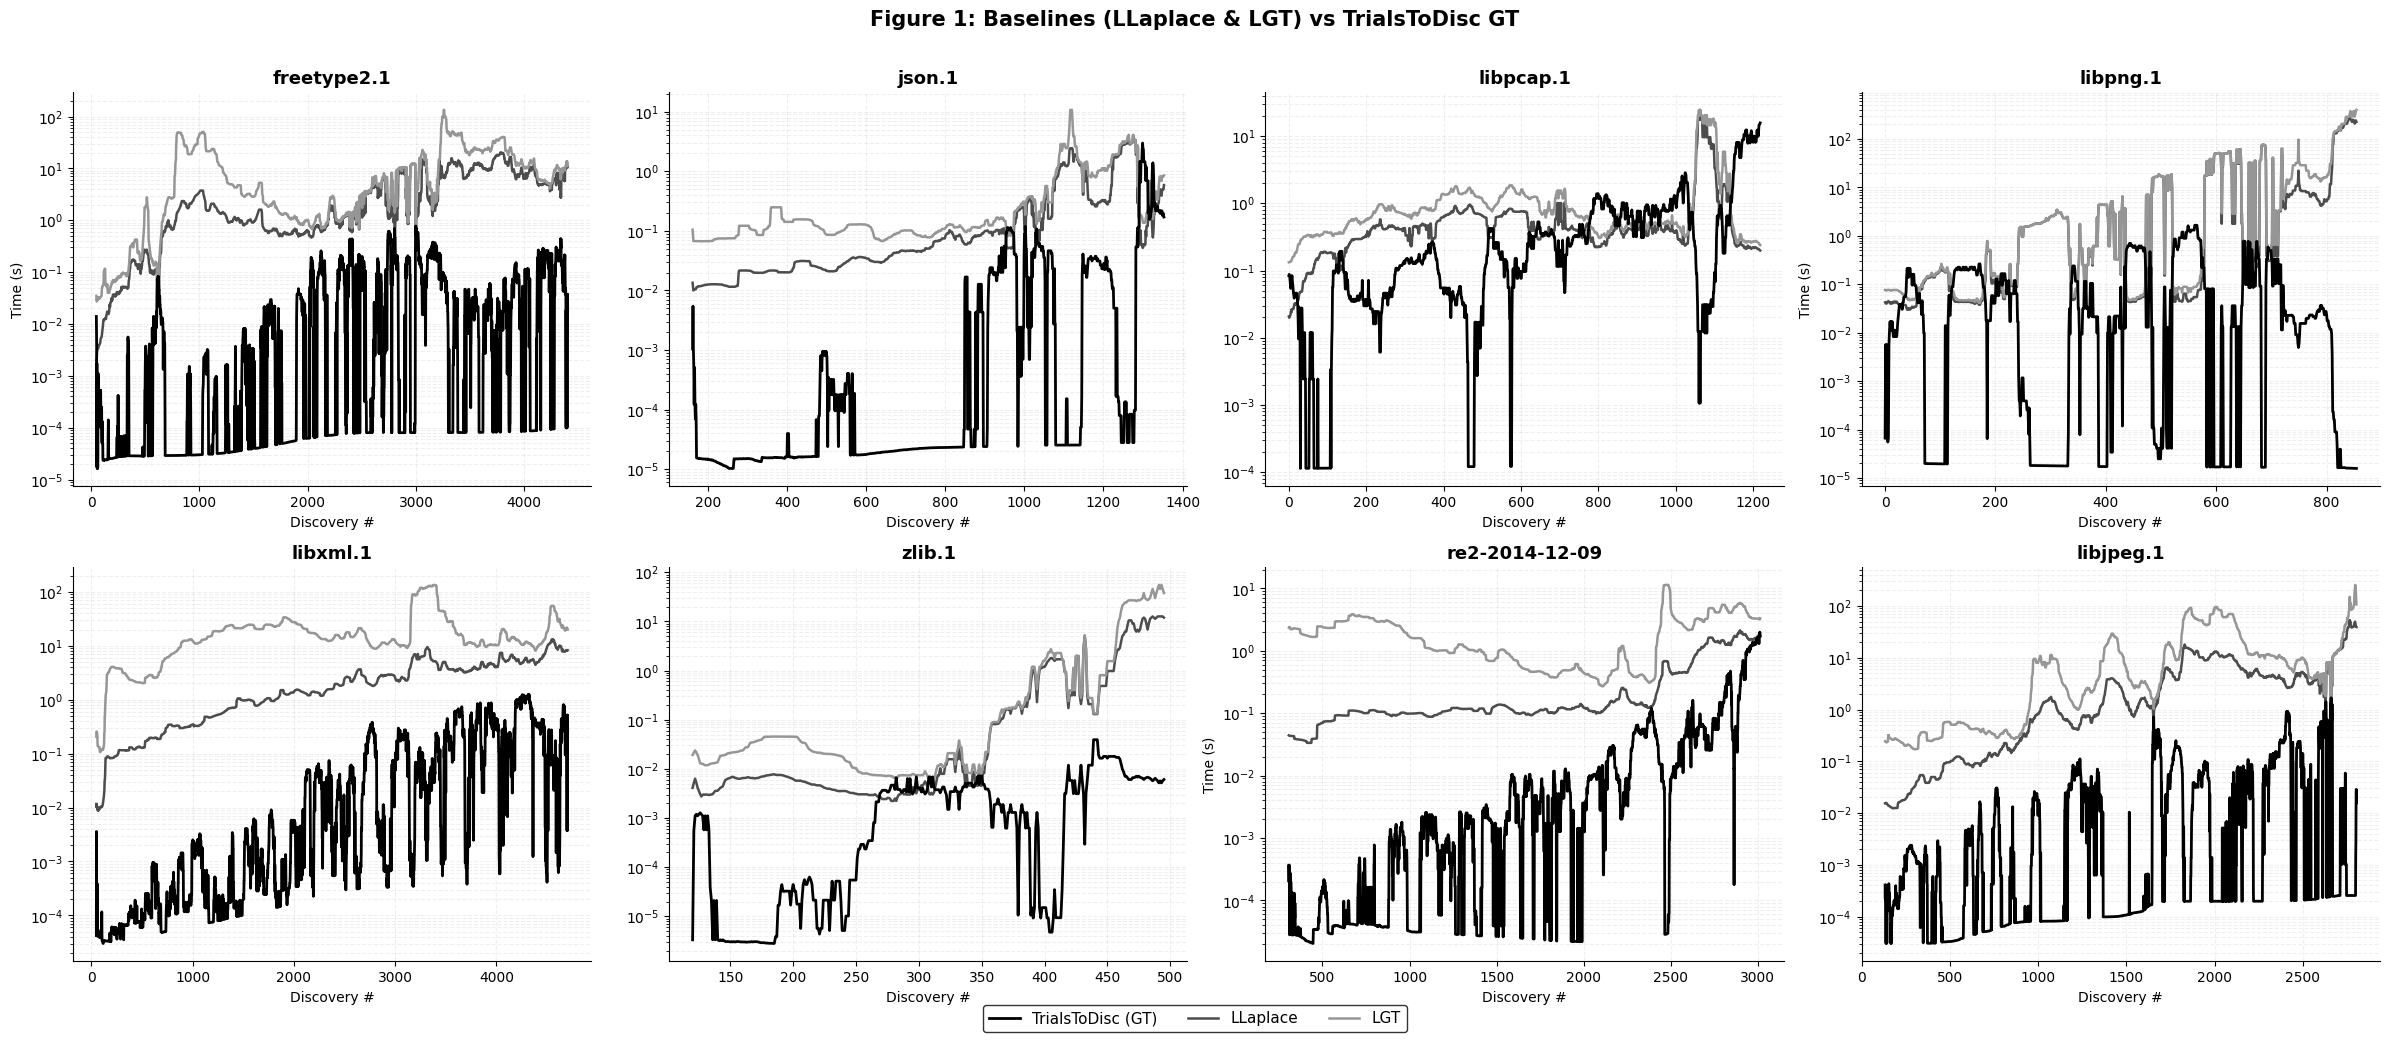

Saved: ./plots/timeseries/fig2_bayes95_bayes99_vs_ttd.jpg


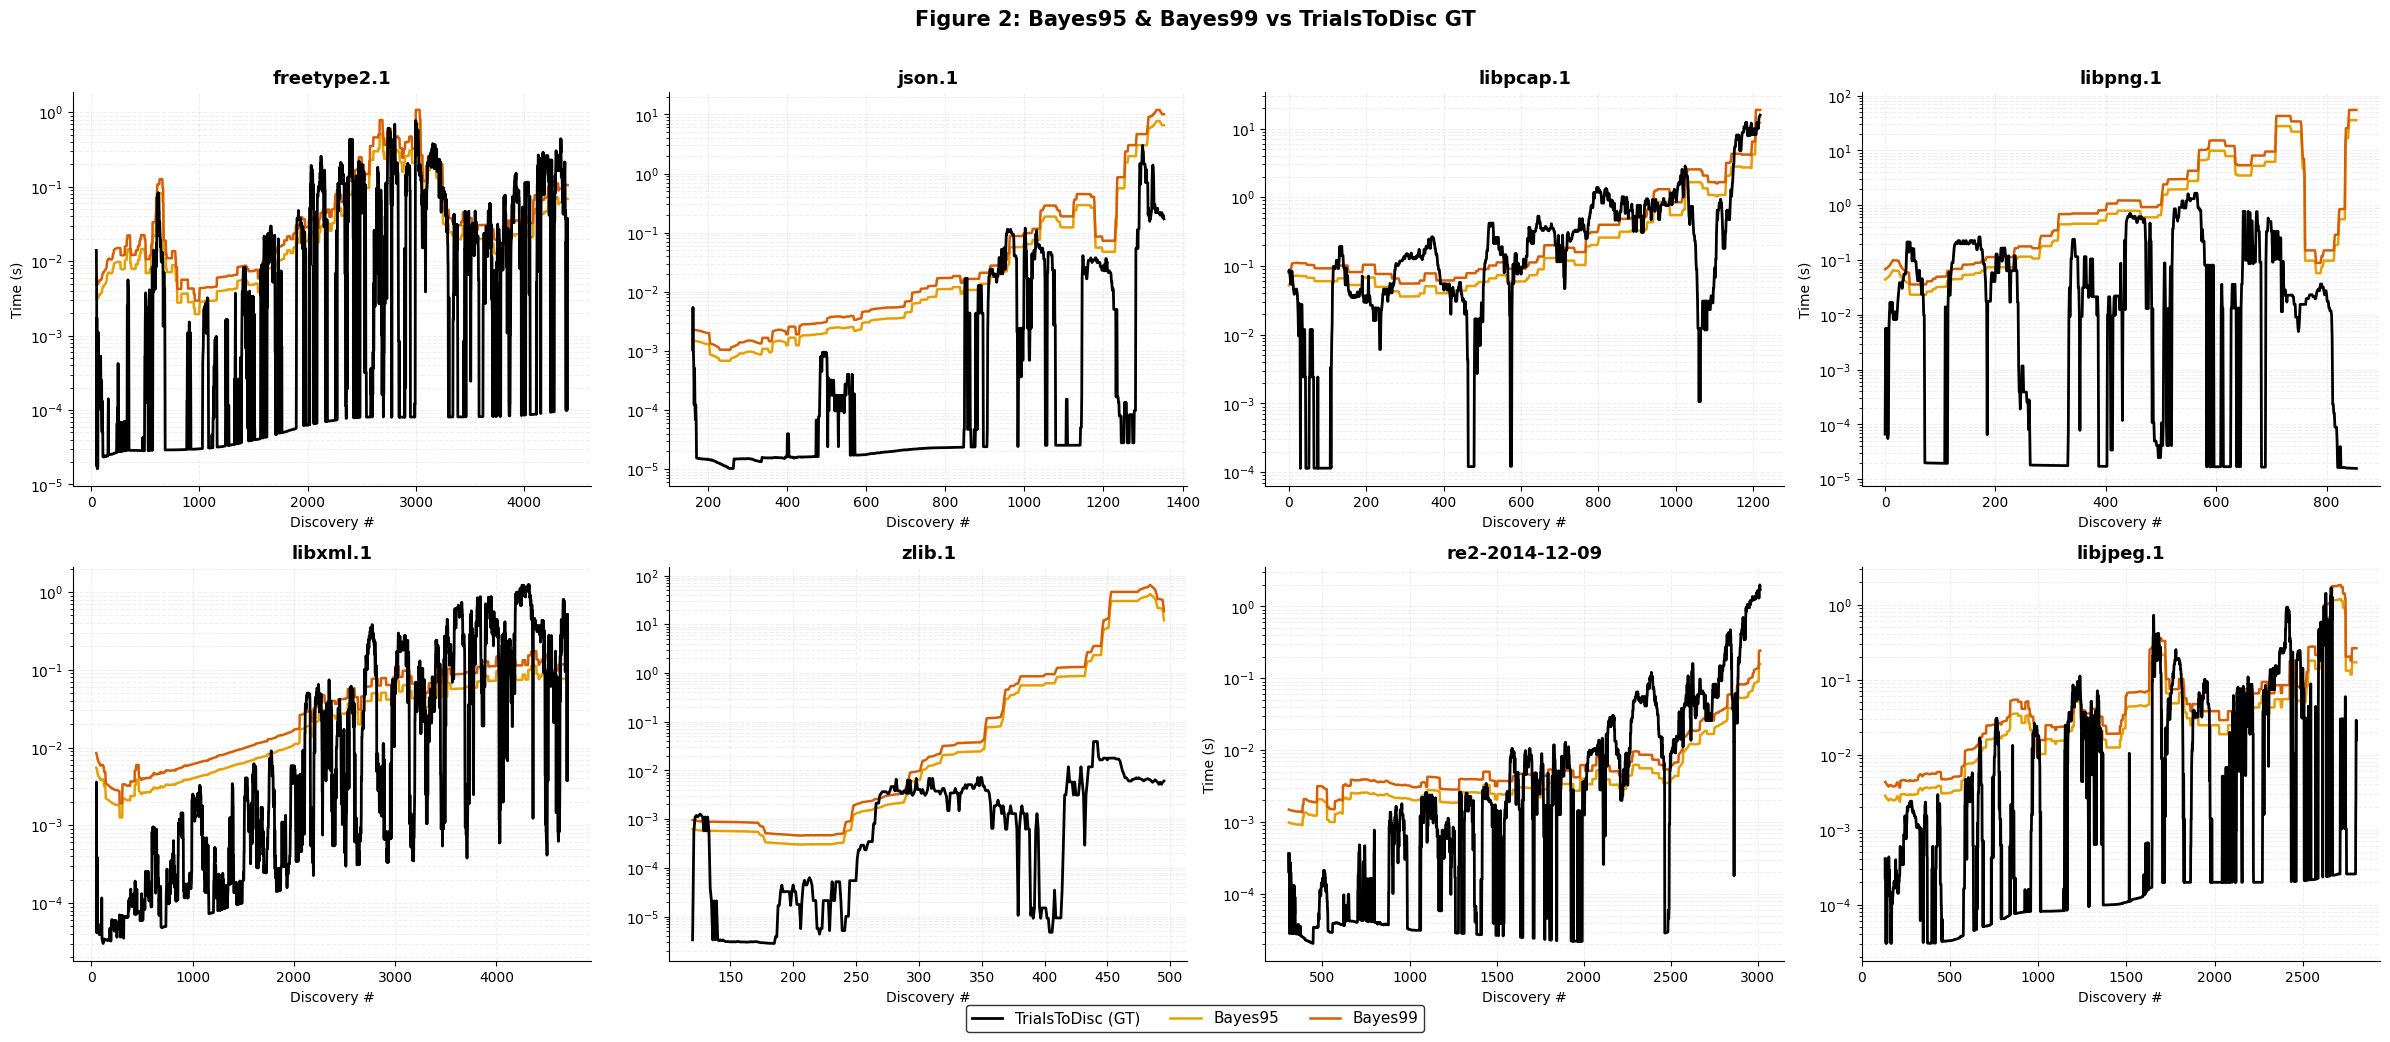

Saved: ./plots/timeseries/fig3_postmean_oraclefree_vs_ttd.jpg


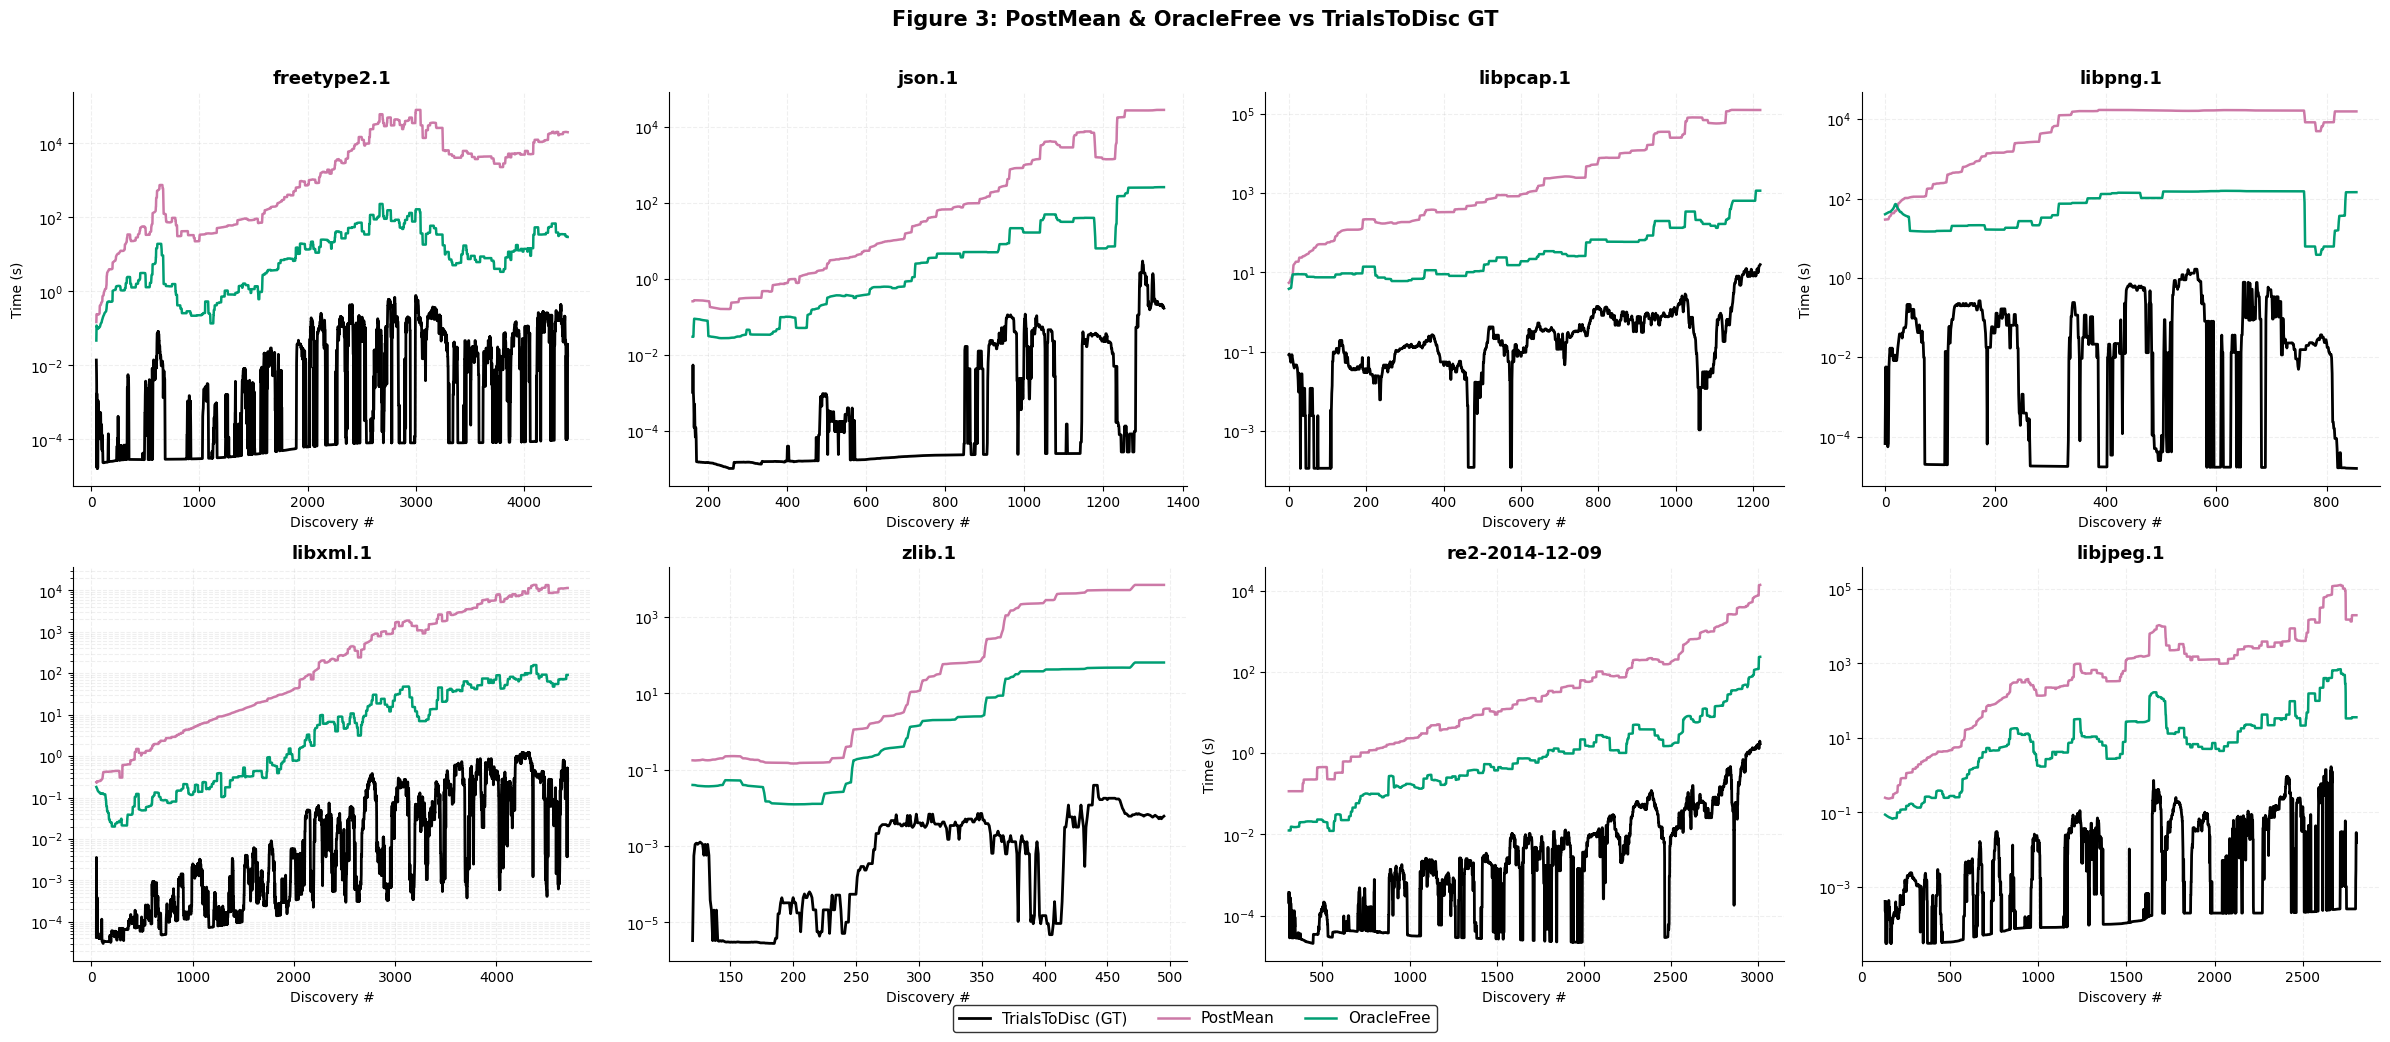

Saved: ./plots/timeseries/fig4_psbayes_vs_ttd.jpg


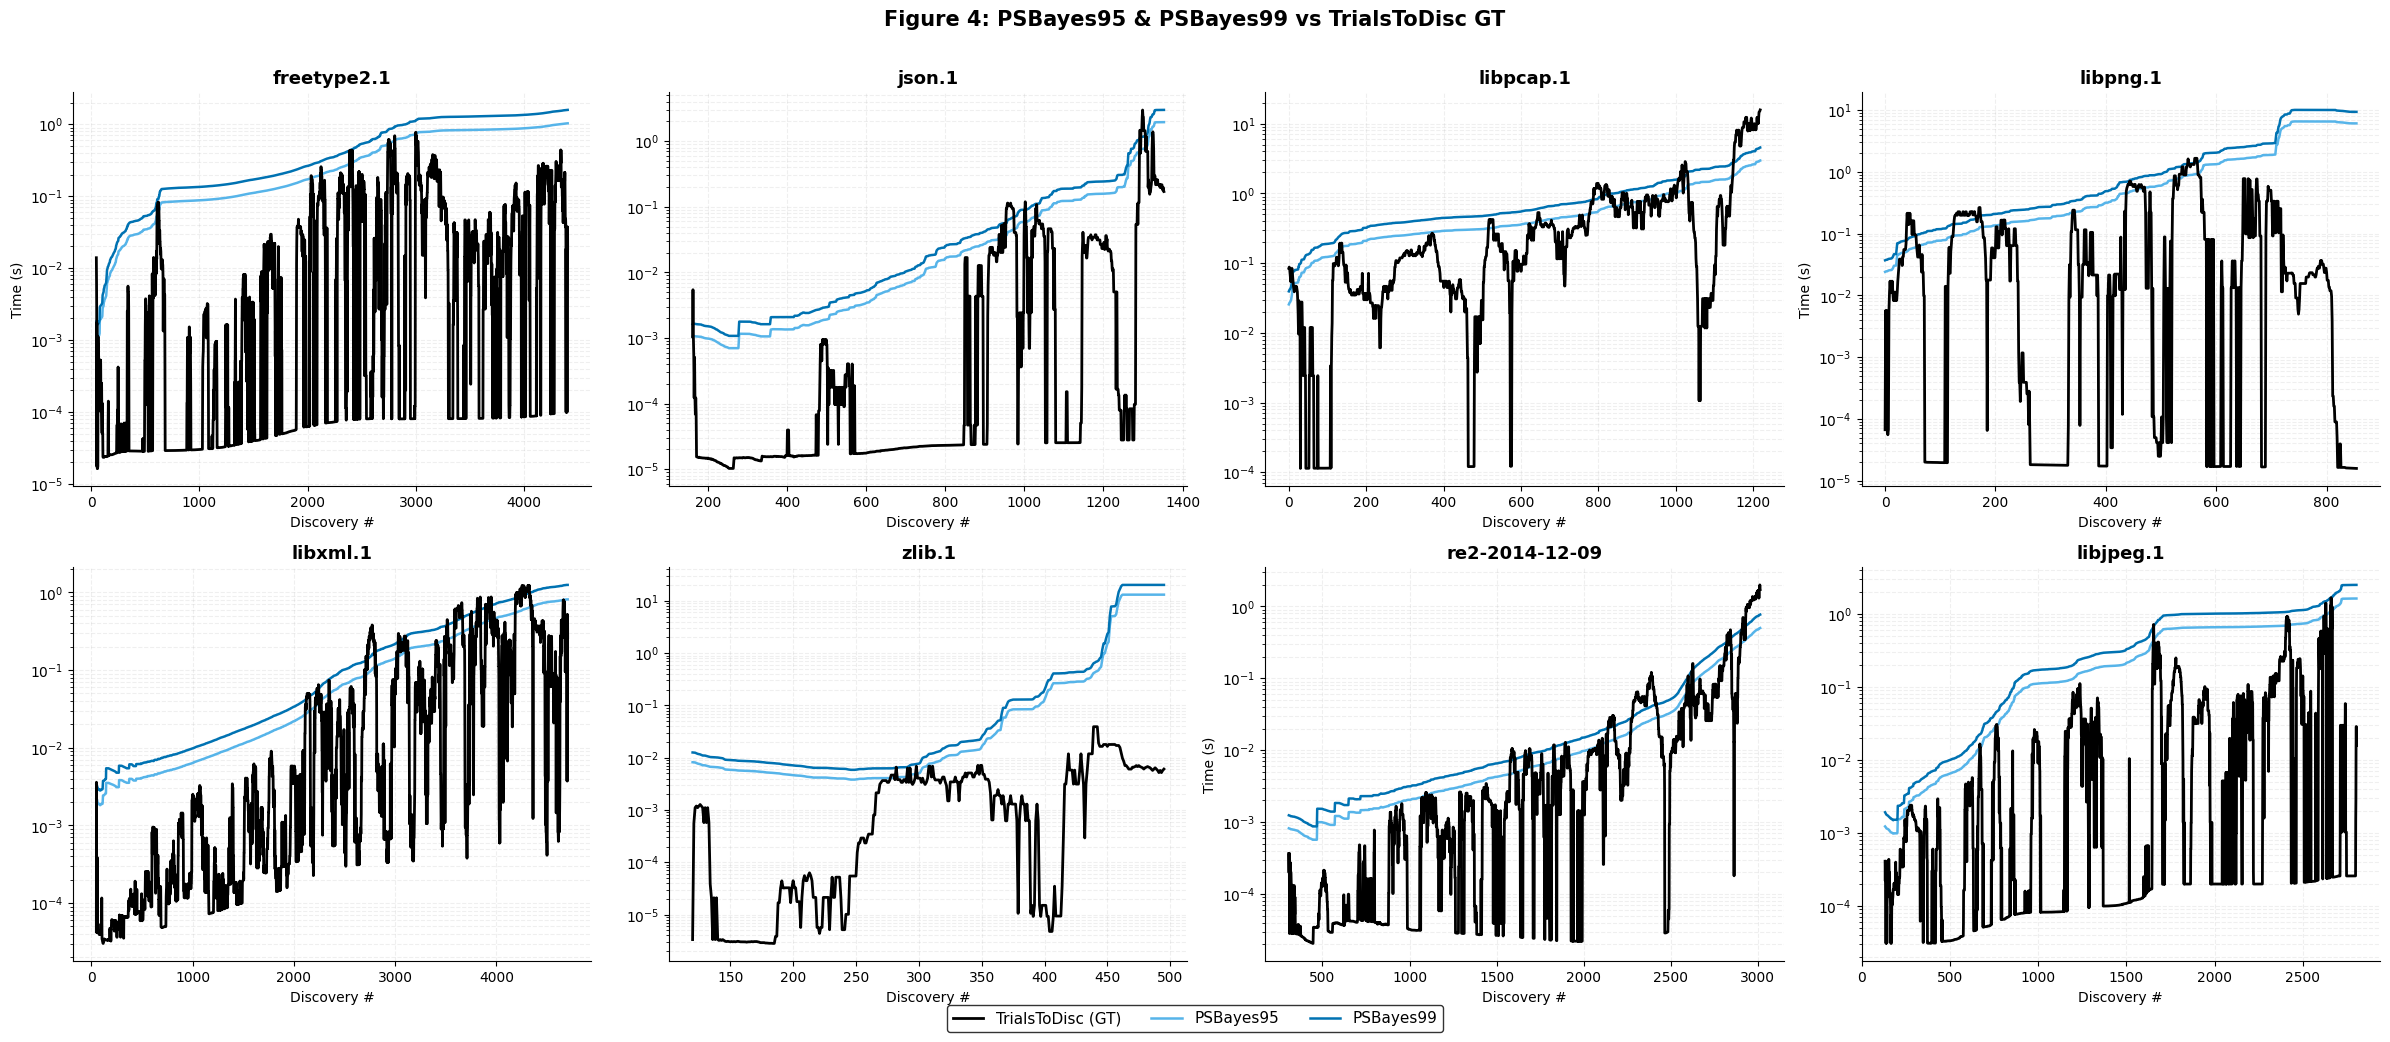

In [19]:
# CELL-15
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
import matplotlib.ticker as ticker

BENCHMARKS = ['freetype2.1', 'json.1', 'libpcap.1', 'libpng.1', 'libxml.1', 'zlib.1', 're2-2014-12-09', 'libjpeg.1']
CSV_DIR    = './data/csv'
PLOT_DIR   = './plots/timeseries'
os.makedirs(PLOT_DIR, exist_ok=True)

SMOOTH_W = 50

def load_ts(bm):
    df  = pd.read_csv(f'{CSV_DIR}/{bm}.csv')
    df  = df.iloc[1:].reset_index(drop=True)  # skip row 0 (all-zero estimates)
    r   = df['Rate'].replace(0, np.nan)
    gt_mf  = df['MaxFork']     / r   # ground truth for baselines
    gt_ttd = df['TrialsToDisc'] / r   # ground truth for our estimators
    return df, r, gt_mf, gt_ttd

def smooth(s, w=SMOOTH_W):
    return s.rolling(w, center=True, min_periods=1).median()

def make_figure(fig_tag, gt_key, estimator_cols, estimator_labels, colors, save_name):
    """
    gt_key           : 'maxfork' or 'ttd'
    estimator_cols   : list of CSV column names to plot
    estimator_labels : display names
    """
    fig, axes = plt.subplots(2, 4, figsize=(24, 10), sharey=False)
    axes = axes.flatten()

    for idx, bm in enumerate(BENCHMARKS):
        ax = axes[idx]
        df, r, gt_mf, gt_ttd = load_ts(bm)
        x  = np.arange(len(df))
        gt = gt_mf if gt_key == 'maxfork' else gt_ttd

        # ground truth
        gt_label = 'MaxFork (GT)' if gt_key == 'maxfork' else 'TrialsToDisc (GT)'
        ax.plot(x, smooth(gt), color='black', lw=2, label=gt_label, zorder=5)

        # estimators
        for col, lbl, clr in zip(estimator_cols, estimator_labels, colors):
            ax.plot(x, smooth(df[col] / r), color=clr, lw=1.8, label=lbl)

        ax.set_yscale('log')
        ax.set_title(bm, fontsize=13, fontweight='bold')
        ax.set_xlabel('Discovery #', fontsize=10)
        if idx % 3 == 0:
            ax.set_ylabel('Time (s)', fontsize=10)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.grid(True, which='both', alpha=0.2, linestyle='--')

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncol=len(labels),
               fontsize=11, frameon=True, edgecolor='black',
               bbox_to_anchor=(0.5, -0.02))
    fig.suptitle(fig_tag, fontsize=15, fontweight='bold', y=1.01)
    plt.tight_layout()
    path = f'{PLOT_DIR}/{save_name}.jpg'
    plt.savefig(path, dpi=200, bbox_inches='tight')
    print(f'Saved: {path}')
    plt.show(); plt.close()

# --- Figure 3: PostMean + OracleFree vs TTD GT ---
make_figure(
    fig_tag          = 'Figure 3: PostMean & OracleFree vs TrialsToDisc GT',
    gt_key           = 'ttd',
    estimator_cols   = ['PostMean_all', 'OracleFree'],
    estimator_labels = ['PostMean', 'OracleFree'],
    colors           = ['#CC79A7', '#009E73'],  # PostMean, OracleFree
    save_name        = 'fig3_postmean_oraclefree_vs_ttd',
)

# --- Figure 4: PSBayes vs TTD GT ---
make_figure(
    fig_tag          = 'Figure 4: PSBayes95 & PSBayes99 vs TrialsToDisc GT',
    gt_key           = 'ttd',
    estimator_cols   = ['PSBayes95', 'PSBayes99'],
    estimator_labels = ['PSBayes95', 'PSBayes99'],
    colors           = ['#56B4E9', '#0072B2'],  # PSBayes95, PSBayes99
    save_name        = 'fig4_psbayes_vs_ttd',
)


In [21]:
# CELL-16: m* values produced by each adaptive method (MW / OracleFree / PerSeed)
# Per benchmark: mean, median, p25, p75, min, max across all rounds.
# Answers the reviewer question: 'what value of m* are you using?'

import numpy as np
import pandas as pd

file_names = ['freetype2.1', 'json.1', 'libpcap.1', 'libpng.1', 'libxml.1', 'zlib.1', 're2-2014-12-09', 'libjpeg.1']

rows = []
for fn in file_names:
    all_ret = parse_file(f'./data/raw/{fn}_run2.txt')
    all_ret_so_far = {}
    psb_model = PerSeedBayesModel(pq=0.95)
    mw_vals, of_vals, ps_vals = [], [], []
    for i in range(len(all_ret)):
        if i > 0:
            mw_vals.append(calculate_m_star(all_ret_so_far, window_size=20, use_scaling=False))
            of_vals.append(m_star_max_total(all_ret_so_far, window_size=20))
            ps_vals.append(psb_model.compute_m_star())
        all_ret_so_far[i] = all_ret[i]
        psb_model.update(all_ret[i])
    for name, vals in [('MovingWindow', mw_vals), ('OracleFree', of_vals), ('PerSeed', ps_vals)]:
        a = np.array(vals, dtype=float)
        rows.append({
            'Benchmark': fn,
            'Method':    name,
            'mean':      round(float(np.mean(a)), 1),
            'median':    round(float(np.median(a)), 1),
            'p25':       round(float(np.percentile(a, 25)), 1),
            'p75':       round(float(np.percentile(a, 75)), 1),
            'min':       round(float(np.min(a)), 1),
            'max':       round(float(np.max(a)), 1),
        })

df_mstar = pd.DataFrame(rows)
df_mstar.to_csv('./data/csv/mstar_values_per_method.csv', index=False)
print('Saved: data/csv/mstar_values_per_method.csv')
print()
print('Per-benchmark m* values:')
print(df_mstar.to_string(index=False))
print()
print('Averages across benchmarks:')
agg = df_mstar.groupby('Method')[['mean', 'median', 'p25', 'p75', 'min', 'max']].mean().round(1)
print(agg.to_string())


Saved: data/csv/mstar_values_per_method.csv

Per-benchmark m* values:
     Benchmark       Method      mean   median      p25       p75     min        max
   freetype2.1 MovingWindow     142.9     50.0     30.0     120.0     4.0     1630.0
   freetype2.1   OracleFree   36406.9  12939.0   4667.0   45784.0     4.0   355374.0
   freetype2.1      PerSeed     899.1    523.2    470.8    1706.2     1.5     1742.7
        json.1 MovingWindow    2510.3     30.0     15.0     316.0     6.0    57130.0
        json.1   OracleFree  200945.1   3678.0    358.0   37598.0     6.0  3801922.0
        json.1      PerSeed     678.3     49.6     13.9     440.6     2.1    12358.7
     libpcap.1 MovingWindow     807.2    120.0     70.0     475.0    25.0    16206.0
     libpcap.1   OracleFree   85251.2  21232.0   7843.2   67727.8  1065.0  1136854.0
     libpcap.1      PerSeed     844.8    498.1    354.8    1029.4     5.2     4286.6
      libpng.1 MovingWindow   53953.7   4405.0    586.0   20583.0   100.0   9305

## 9. RQ4: PSBayes-stop + Coverage-Saturation

Saved: data/csv/rq1_true_grid_per_bench.csv
Saved: data/csv/rq1_true_grid_smape_avg.csv
Saved: data/csv/rq1_true_grid_under_avg.csv

Average W-SMAPE grid (rows = m*, cols = q):
        q=0.95  q=0.96  q=0.97  q=0.98  q=0.99
m_star                                        
10      262.46  261.46  260.23  258.58  255.99
50      235.22  233.81  232.13  229.94  226.62
100     221.29  219.79  217.99  215.72  212.41
500     192.96  192.12  191.19  190.13  188.72
1000    186.88  186.50  186.12  185.69  185.20
5000    185.61  185.76  185.93  186.15  186.52
10000   187.18  187.38  187.65  188.01  188.54
50000   191.53  191.71  191.92  192.19  192.58
100000  193.19  193.38  193.59  193.85  194.22

Average Under% grid (rows = m*, cols = q):
        q=0.95  q=0.96  q=0.97  q=0.98  q=0.99
10       48.25   48.02   47.79   47.45   46.85
50       41.66   41.20   40.73   40.17   39.36
100      37.85   37.46   36.93   36.13   34.86
500      25.21   24.72   23.86   22.98   21.67
1000     19.60   18.91   18

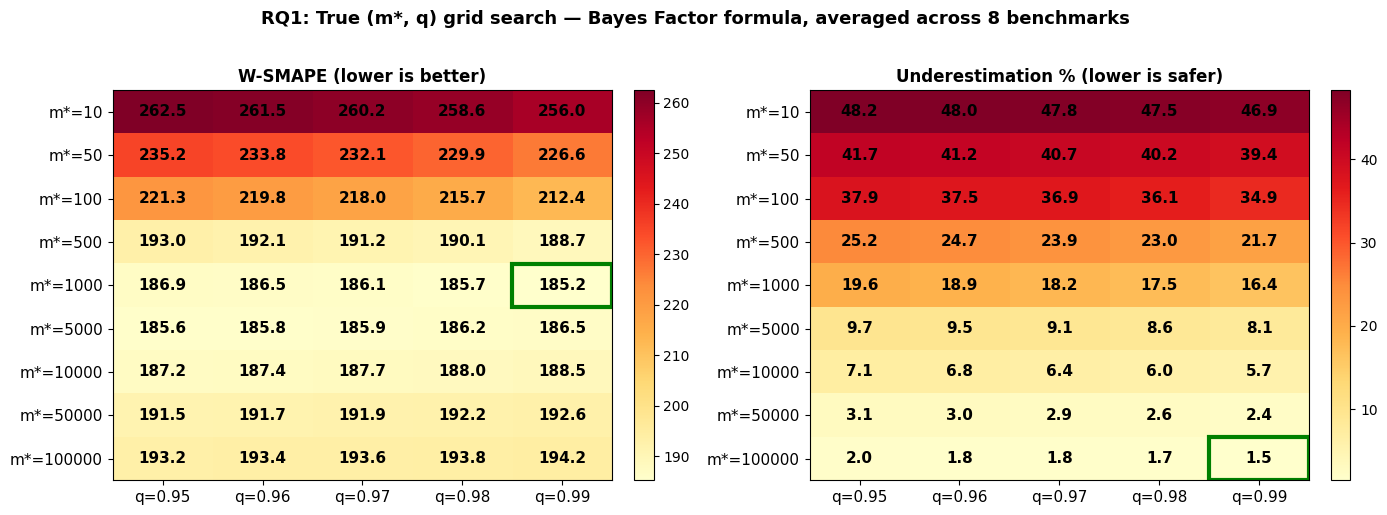

Saved: plots/rq1_true_grid_heatmap.jpg


In [22]:
# CELL-17: True (m*, q) grid search — fixed numerical m* values swept against q.
# We perform a real grid search over both hyperparameters. We fix m* as a
# constant across all rounds and sweep over q. For each (m*, q) cell we compute
# the Bayes Factor prediction at every round and report aggregated metrics.

import math, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs('./plots', exist_ok=True)

M_STAR_GRID = [10, 50, 100, 500, 1000, 5000, 10000, 50000, 100000]
Q_GRID      = [0.95, 0.96, 0.97, 0.98, 0.99]
R_FIXED     = 100
file_names  = ['freetype2.1', 'json.1', 'libpcap.1', 'libpng.1', 'libxml.1', 'zlib.1', 're2-2014-12-09', 'libjpeg.1']

def predict_const_mstar(m_star, q, l):
    m_star = min(m_star, 1e6)
    R_power = math.exp(math.log(R_FIXED) / max(1, l))
    theta_star = 1.0 / ((m_star + 1) * (R_power + 1))
    theta_star = max(1e-10, min(theta_star, 1 - 1e-10))
    try:
        return math.log(1 - q) / math.log(1 - theta_star)
    except (ValueError, ZeroDivisionError):
        return 1e9

def cell_metrics(y_true, y_pred, rate):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    rate   = np.asarray(rate,   dtype=float)
    mask = np.isfinite(y_true) & np.isfinite(y_pred) & (y_true > 0) & (y_pred > 0) & (rate != 0)
    yt, yp, r = y_true[mask], y_pred[mask], rate[mask]
    yt, yp = yt / r, yp / r
    errs = yp - yt
    under = errs < 0
    over  = errs > 0
    ue_pct = round(float(np.sum(under) / max(1, len(errs)) * 100), 2)
    oe_max = round(float(np.log10(np.max(errs[over]))  if np.any(over) else 0.0), 2)
    oe_avg = round(float(np.log10(np.mean(errs[over])) if np.any(over) else 0.0), 2)
    denom  = np.clip((np.abs(yt) + np.abs(yp)) / 2.0, 1e-9, None)
    w      = np.where(yp < yt, 2.0, 1.0)
    smape  = round(float(np.mean(w * np.abs(errs) / denom) * 100), 2)
    return smape, ue_pct, oe_max, oe_avg

grid_smape = np.zeros((len(M_STAR_GRID), len(Q_GRID)))
grid_under = np.zeros((len(M_STAR_GRID), len(Q_GRID)))
grid_oemax = np.zeros((len(M_STAR_GRID), len(Q_GRID)))
grid_oeavg = np.zeros((len(M_STAR_GRID), len(Q_GRID)))

per_bench_rows = []

for i, m_star in enumerate(M_STAR_GRID):
    for j, q in enumerate(Q_GRID):
        s_acc, u_acc, mx_acc, av_acc = [], [], [], []
        for fn in file_names:
            df  = pd.read_csv(f'./data/csv/{fn}.csv').iloc[1:].reset_index(drop=True)
            ttd  = df['TrialsToDisc'].values.astype(float)
            rate = pd.to_numeric(df['Rate'], errors='coerce').fillna(1.0).values.astype(float)
            preds = np.array([predict_const_mstar(m_star, q, l) for l in range(1, len(df) + 1)])
            sm, ue, om, oa = cell_metrics(ttd, preds, rate)
            s_acc.append(sm); u_acc.append(ue); mx_acc.append(om); av_acc.append(oa)
            per_bench_rows.append({
                'm_star': m_star, 'q': q, 'Benchmark': fn,
                'SMAPE': sm, 'Under%': ue, 'OE-Max': om, 'OE-Avg': oa,
            })
        grid_smape[i, j] = round(float(np.mean(s_acc)), 2)
        grid_under[i, j] = round(float(np.mean(u_acc)), 2)
        grid_oemax[i, j] = round(float(np.mean(mx_acc)), 2)
        grid_oeavg[i, j] = round(float(np.mean(av_acc)), 2)

# --- Save full per-benchmark CSV ---
pd.DataFrame(per_bench_rows).to_csv('./data/csv/rq1_true_grid_per_bench.csv', index=False)

# --- Save averaged grid CSV ---
df_avg = pd.DataFrame(grid_smape, index=M_STAR_GRID, columns=[f'q={q}' for q in Q_GRID])
df_avg.index.name = 'm_star'
df_avg.to_csv('./data/csv/rq1_true_grid_smape_avg.csv')
pd.DataFrame(grid_under, index=M_STAR_GRID, columns=[f'q={q}' for q in Q_GRID])\
  .rename_axis('m_star').to_csv('./data/csv/rq1_true_grid_under_avg.csv')

print('Saved: data/csv/rq1_true_grid_per_bench.csv')
print('Saved: data/csv/rq1_true_grid_smape_avg.csv')
print('Saved: data/csv/rq1_true_grid_under_avg.csv')
print()
print('Average W-SMAPE grid (rows = m*, cols = q):')
print(df_avg.round(2).to_string())
print()
print('Average Under% grid (rows = m*, cols = q):')
print(pd.DataFrame(grid_under, index=M_STAR_GRID, columns=[f'q={q}' for q in Q_GRID]).round(2).to_string())

# --- Find best cell on each axis ---
best_smape_idx = np.unravel_index(np.argmin(grid_smape), grid_smape.shape)
best_under_idx = np.unravel_index(np.argmin(grid_under), grid_under.shape)
print()
print(f'Best SMAPE: m*={M_STAR_GRID[best_smape_idx[0]]}, q={Q_GRID[best_smape_idx[1]]} -> {grid_smape[best_smape_idx]:.2f}')
print(f'Best Under%: m*={M_STAR_GRID[best_under_idx[0]]}, q={Q_GRID[best_under_idx[1]]} -> {grid_under[best_under_idx]:.2f}%')

# --- Plot heatmaps (true grid) ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, mat, title, best in [
    (axes[0], grid_smape, 'W-SMAPE (lower is better)',         best_smape_idx),
    (axes[1], grid_under, 'Underestimation % (lower is safer)', best_under_idx),
]:
    im = ax.imshow(mat, cmap='YlOrRd', aspect='auto')
    ax.set_xticks(range(len(Q_GRID))); ax.set_xticklabels([f'q={q}' for q in Q_GRID], fontsize=11)
    ax.set_yticks(range(len(M_STAR_GRID))); ax.set_yticklabels([f'm*={m}' for m in M_STAR_GRID], fontsize=11)
    ax.set_title(title, fontsize=12, fontweight='bold')
    for i in range(len(M_STAR_GRID)):
        for j in range(len(Q_GRID)):
            ax.text(j, i, f'{mat[i, j]:.1f}', ha='center', va='center',
                    fontsize=11, fontweight='bold', color='black')
    from matplotlib.patches import Rectangle
    bi, bj = best
    ax.add_patch(Rectangle((bj - 0.5, bi - 0.5), 1, 1, fill=False, edgecolor='green', linewidth=3))
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.suptitle('RQ1: True (m*, q) grid search — Bayes Factor formula, averaged across 8 benchmarks',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('./plots/rq1_true_grid_heatmap.jpg', dpi=200, bbox_inches='tight')
plt.show()
print('Saved: plots/rq1_true_grid_heatmap.jpg')


In [23]:
# CELL-18: Estimated variance across benchmarks
# For each estimator and each metric (SMAPE, Under%, OE-Max, OE-Avg),
# compute mean and standard deviation across the 8 benchmarks.
# This is included so that table averages can be reported as mean +/- std.

import numpy as np
import pandas as pd

df = pd.read_csv('./data/csv/table2_complete.csv')

BASELINES = ['LL', 'LGT']
OURS      = ['B95', 'B99', 'PM', 'OF', 'PS95', 'PS99', 'PSPM']
METRICS   = ['SMAPE', 'UE-Pct', 'OE-Max', 'OE-Avg']

rows = []
for est in BASELINES + OURS:
    row = {'Estimator': est, 'Group': 'baseline' if est in BASELINES else 'ours'}
    for m in METRICS:
        vals = df[f'{est}_{m}'].astype(float)
        row[f'{m}_mean'] = round(float(vals.mean()), 2)
        row[f'{m}_std']  = round(float(vals.std(ddof=1)), 2)
        row[f'{m}_min']  = round(float(vals.min()), 2)
        row[f'{m}_max']  = round(float(vals.max()), 2)
    rows.append(row)

summary = pd.DataFrame(rows)
summary.to_csv('./data/csv/estimator_variance_summary.csv', index=False)
print('Saved: data/csv/estimator_variance_summary.csv')
print()

# Print a clean summary table
print('Mean +/- Std (n=8 benchmarks):')
print()
hdr = f"{'Estimator':<10} {'SMAPE':>18} {'Under%':>18} {'OE-Max (log10)':>22} {'OE-Avg (log10)':>22}"
print(hdr)
print('-' * len(hdr))
for _, r in summary.iterrows():
    sm = f"{r['SMAPE_mean']:>6.2f} +/- {r['SMAPE_std']:.2f}"
    ue = f"{r['UE-Pct_mean']:>6.2f} +/- {r['UE-Pct_std']:.2f}"
    mx = f"{r['OE-Max_mean']:>6.2f} +/- {r['OE-Max_std']:.2f}"
    av = f"{r['OE-Avg_mean']:>6.2f} +/- {r['OE-Avg_std']:.2f}"
    print(f"{r['Estimator']:<10} {sm:>18} {ue:>18} {mx:>22} {av:>22}")


Saved: data/csv/estimator_variance_summary.csv

Mean +/- Std (n=8 benchmarks):

Estimator               SMAPE             Under%         OE-Max (log10)         OE-Avg (log10)
----------------------------------------------------------------------------------------------
LL           204.06 +/- 32.47    22.31 +/- 15.51          2.32 +/- 0.99          0.82 +/- 0.80
LGT          204.60 +/- 27.21    18.00 +/- 15.46          2.85 +/- 0.78          1.33 +/- 0.64
B95          216.50 +/- 11.57     40.91 +/- 5.88          0.55 +/- 1.04         -0.66 +/- 1.06
B99          203.34 +/- 10.54     37.46 +/- 6.33          0.74 +/- 1.04         -0.48 +/- 1.06
PM            199.51 +/- 0.28      0.01 +/- 0.04          4.56 +/- 0.52          3.61 +/- 0.52
OF            190.53 +/- 1.50      0.36 +/- 0.79          2.61 +/- 0.47          1.48 +/- 0.38
PS95         191.22 +/- 16.80     32.65 +/- 7.58          0.34 +/- 0.47         -0.50 +/- 0.61
PS99         180.45 +/- 16.58     28.36 +/- 6.96          0.53 +/

      label  under  smape      group
   LLaplace  22.31 204.06   baseline
        LGT  18.00 204.60   baseline
 Bayes95-MW  40.91 216.50   bayes_mw
 Bayes99-MW  37.46 203.34   bayes_mw
PostMean-MW   0.02 199.51   postmean
 OracleFree   0.36 190.53 oraclefree
  PSBayes95  32.65 191.22 psbayes_bf
  PSBayes99  28.36 180.45 psbayes_bf
  PSBayesPM   0.04 199.58   postmean


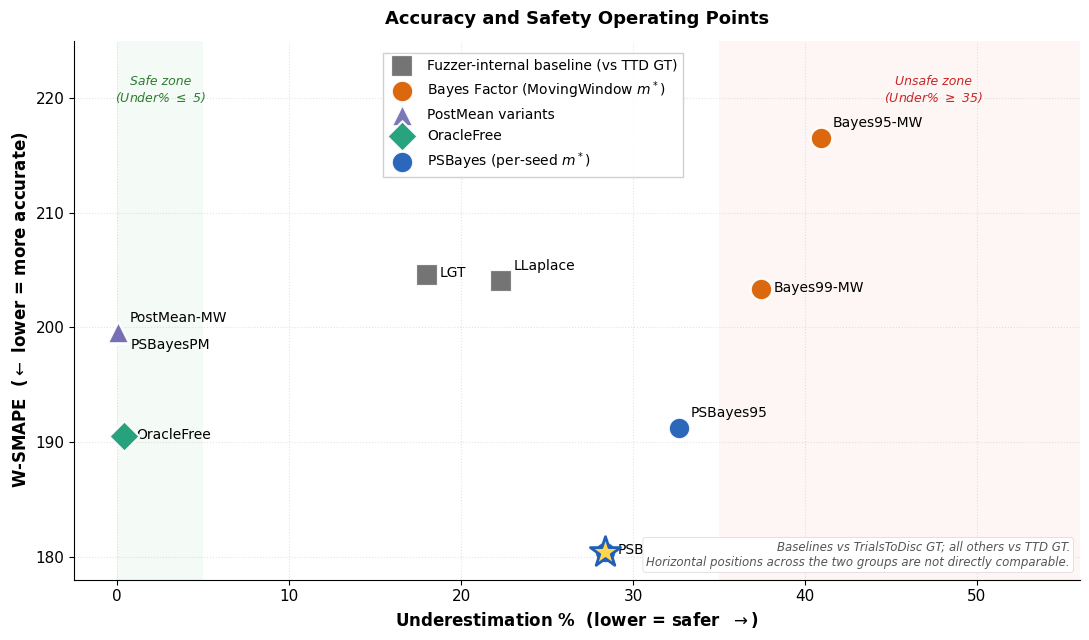

Saved: ./plots/rq3_tradeoff_scatter.jpg


In [24]:
# CELL-19
# Accuracy / Safety trade-off scatter (clean redesign)
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

os.makedirs('./plots', exist_ok=True)
plt.rcParams['font.family'] = 'DejaVu Sans'

df = pd.read_csv('./data/csv/table2_complete.csv')

EST_INFO = [
    ('LLaplace',     'LL',   'baseline'),
    ('LGT',          'LGT',  'baseline'),
    ('Bayes95-MW',   'B95',  'bayes_mw'),
    ('Bayes99-MW',   'B99',  'bayes_mw'),
    ('PostMean-MW',  'PM',   'postmean'),
    ('OracleFree',   'OF',   'oraclefree'),
    ('PSBayes95',    'PS95', 'psbayes_bf'),
    ('PSBayes99',    'PS99', 'psbayes_bf'),
    ('PSBayesPM',    'PSPM', 'postmean'),
]

GROUP_STYLE = {
    'baseline':    {'color': '#6c6c6c', 'marker': 's', 'label': 'Fuzzer-internal baseline (vs TTD GT)'},
    'bayes_mw':    {'color': '#d95f02', 'marker': 'o', 'label': 'Bayes Factor (MovingWindow $m^*$)'},
    'oraclefree':  {'color': '#1b9e77', 'marker': 'D', 'label': 'OracleFree'},
    'psbayes_bf':  {'color': '#1f5fb7', 'marker': 'o', 'label': 'PSBayes (per-seed $m^*$)'},
    'postmean':    {'color': '#7570b3', 'marker': '^', 'label': 'PostMean variants'},
}

rows = []
for label, prefix, group in EST_INFO:
    rows.append({
        'label':  label,
        'under':  df[f'{prefix}_UE-Pct'].mean(),
        'smape':  df[f'{prefix}_SMAPE'].mean(),
        'group':  group,
    })
data = pd.DataFrame(rows)
print(data.round(2).to_string(index=False))

# --- Plot ---
fig, ax = plt.subplots(1, 1, figsize=(11, 6.5))
fig.patch.set_facecolor('white')

# Soft background zones to convey meaning
ax.axvspan(0, 5,   ymin=0, ymax=1, facecolor='#e8f5e9', alpha=0.45, zorder=0)
ax.axvspan(35, 60, ymin=0, ymax=1, facecolor='#fdecea', alpha=0.45, zorder=0)
ax.text(2.5, 222, 'Safe zone\n(Under% $\\leq$ 5)', ha='center', va='top',
        fontsize=9, color='#2e7d32', style='italic')
ax.text(47.5, 222, 'Unsafe zone\n(Under% $\\geq$ 35)', ha='center', va='top',
        fontsize=9, color='#c62828', style='italic')

# Plot estimator points
seen = set()
for _, r in data.iterrows():
    style = GROUP_STYLE[r['group']]
    show_label = style['label'] if r['group'] not in seen else None
    seen.add(r['group'])
    ax.scatter(r['under'], r['smape'], s=240,
               color=style['color'], marker=style['marker'],
               edgecolor='white', linewidth=1.6, alpha=0.95,
               zorder=4, label=show_label)

# Smart annotation placement: avoid overlap
label_offsets = {
    'LLaplace':    ( 9,   8),
    'LGT':         ( 9,  -2),
    'Bayes95-MW':  ( 9,   8),
    'Bayes99-MW':  ( 9,  -2),
    'PostMean-MW': ( 9,   8),
    'OracleFree':  ( 9,  -2),
    'PSBayes95':   ( 9,   8),
    'PSBayes99':   ( 9,  -2),
    'PSBayesPM':   ( 9,  -12),
}
for _, r in data.iterrows():
    dx, dy = label_offsets[r['label']]
    ax.annotate(r['label'], (r['under'], r['smape']),
                xytext=(dx, dy), textcoords='offset points',
                fontsize=10, color='black')

# Star the recommended accuracy point
ps99 = data[data['label'] == 'PSBayes99'].iloc[0]
ax.scatter([ps99['under']], [ps99['smape']], s=520, marker='*',
           facecolor='#ffd54f', edgecolor='#1f5fb7', linewidth=2,
           zorder=5)

# Axes
ax.set_xlim(-2.5, 56)
ax.set_ylim(178, 225)
ax.set_xlabel('Underestimation %  (lower = safer  $\\rightarrow$)',
              fontsize=12, fontweight='bold')
ax.set_ylabel('W-SMAPE  ($\\leftarrow$ lower = more accurate)',
              fontsize=12, fontweight='bold')
ax.set_title('Accuracy and Safety Operating Points',
             fontsize=13, fontweight='bold', pad=12)

ax.grid(True, linestyle=':', alpha=0.35, zorder=1)
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(labelsize=11)

# Legend at top-left where there's no data
leg = ax.legend(loc='upper left', fontsize=10, frameon=True,
                edgecolor='#cccccc', fancybox=False,
                bbox_to_anchor=(0.30, 0.99))
leg.get_frame().set_alpha(0.92)

# Note about GT split
ax.text(0.99, 0.02,
        'Baselines vs TrialsToDisc GT; all others vs TTD GT.\n'
        'Horizontal positions across the two groups are not directly comparable.',
        transform=ax.transAxes, ha='right', va='bottom',
        fontsize=8.5, style='italic', color='#555555',
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white',
                  edgecolor='#dddddd', linewidth=0.6))

plt.tight_layout()
save_path = './plots/rq3_tradeoff_scatter.jpg'
plt.savefig(save_path, dpi=220, bbox_inches='tight', facecolor='white')
plt.show()
print(f'Saved: {save_path}')


=== Primary operating point: lambda = 5, S = 10 ===
     Benchmark  TotalRounds  StopRound  Captured%  Saved%
   freetype2.1         4403       4403     100.00    0.00
        json.1         1354        758      55.98   99.41
     libpcap.1         1220       1160      95.08   40.38
      libpng.1          855        535      62.57   83.28
      libxml.1         4706       3366      71.53   79.21
        zlib.1          496        375      75.60   98.00
re2-2014-12-09         3015       1658      54.99   94.52
     libjpeg.1         2804        858      30.60   95.95

Mean across 8 benchmarks:
  Captured%: 68.29 +/- 22.58
  Saved%:    73.84 +/- 35.54

=== Lambda sweep (averaged across 8 benchmarks) ===
 lambda  cap_mean  cap_std  sav_mean  sav_std
      3     46.29    26.95     94.08     8.43
      5     68.29    22.58     73.84    35.54
      8     83.29    15.24     51.17    43.34
     12     92.04    11.79     28.47    43.58
     20     94.05     8.89     26.25    40.77


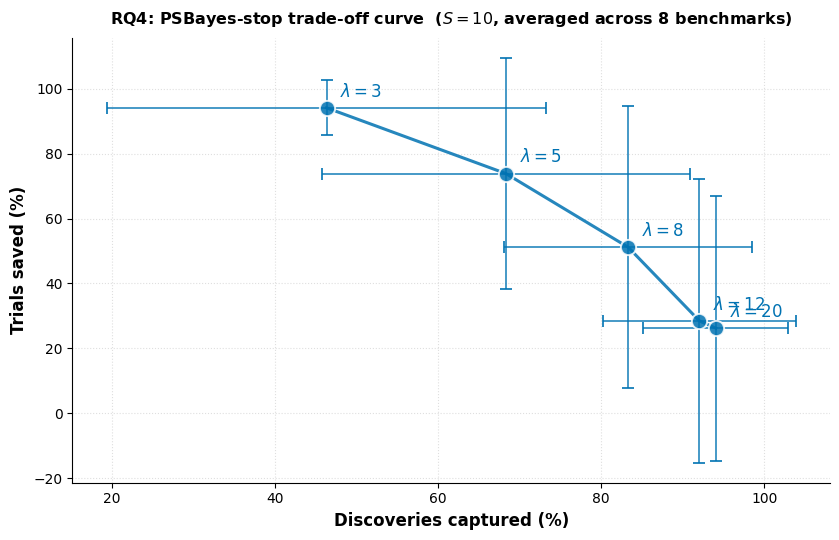


Saved: ./plots/rq4_psbayes_stop_curve.jpg


In [25]:
# CELL-20
# RQ4 -- PSBayes99 as a stopping criterion (sustained-threshold rule).
#
# Rule: stop at round r when PSBayes99's per-round prediction exceeds
# lambda * running_median(pred[:r]) for at least S consecutive rounds.
# Dual criterion (magnitude + persistence) gives a stable saturation signal.

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs('./plots', exist_ok=True)

BENCHMARKS = ['freetype2.1', 'json.1', 'libpcap.1', 'libpng.1', 'libxml.1', 'zlib.1', 're2-2014-12-09', 'libjpeg.1']
WARMUP     = 100
S_PRIMARY  = 10   # persistence -- consecutive rounds above threshold
L_PRIMARY  = 5    # lambda -- magnitude multiplier
L_SWEEP    = [3, 5, 8, 12, 20]

def stop_sustained(pred, lam, S):
    streak = 0
    for r in range(WARMUP, len(pred)):
        med = np.median(pred[:r])
        if med <= 0:
            streak = 0
            continue
        if pred[r] > lam * med:
            streak += 1
            if streak >= S:
                return r
        else:
            streak = 0
    return len(pred)

def evaluate(r_stop, n, cum, total):
    if r_stop >= n:
        return 100.0, 0.0
    return round(100.0 * r_stop / n, 2), round(100.0 * (total - cum[r_stop]) / total, 2)

per_bench, sweep_rows = [], []

for fn in BENCHMARKS:
    df  = pd.read_csv(f'./data/csv/{fn}.csv').iloc[1:].reset_index(drop=True)
    ttd, pred = df['TrialsToDisc'].values.astype(float), df['PSBayes99'].values.astype(float)
    n   = len(ttd)
    cum = np.cumsum(ttd)
    total = cum[-1]
    # primary
    r_stop = stop_sustained(pred, L_PRIMARY, S_PRIMARY)
    cap, saved = evaluate(r_stop, n, cum, total)
    per_bench.append({'Benchmark': fn, 'TotalRounds': n, 'StopRound': r_stop,
                      'Captured%': cap, 'Saved%': saved})
    # sweep
    for lam in L_SWEEP:
        r2 = stop_sustained(pred, lam, S_PRIMARY)
        c2, s2 = evaluate(r2, n, cum, total)
        sweep_rows.append({'Benchmark': fn, 'lambda': lam,
                           'StopRound': r2, 'Captured%': c2, 'Saved%': s2})

df_primary = pd.DataFrame(per_bench)
df_sweep   = pd.DataFrame(sweep_rows)
df_primary.to_csv('./data/csv/rq4_psbayes_stop_primary.csv', index=False)
df_sweep.to_csv('./data/csv/rq4_psbayes_stop_sweep.csv',   index=False)

print(f'=== Primary operating point: lambda = {L_PRIMARY}, S = {S_PRIMARY} ===')
print(df_primary.to_string(index=False))
print(f"\nMean across {len(BENCHMARKS)} benchmarks:")
print(f"  Captured%: {df_primary['Captured%'].mean():.2f} +/- {df_primary['Captured%'].std(ddof=1):.2f}")
print(f"  Saved%:    {df_primary['Saved%'].mean():.2f} +/- {df_primary['Saved%'].std(ddof=1):.2f}")

df_avg = df_sweep.groupby('lambda').agg(
    cap_mean=('Captured%','mean'), cap_std=('Captured%', 'std'),
    sav_mean=('Saved%','mean'),    sav_std=('Saved%','std')
).round(2).reset_index()
df_avg.to_csv('./data/csv/rq4_psbayes_stop_avg.csv', index=False)
print('\n=== Lambda sweep (averaged across 8 benchmarks) ===')
print(df_avg.to_string(index=False))

# --- Trade-off curve ---
fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.errorbar(df_avg['cap_mean'], df_avg['sav_mean'],
            xerr=df_avg['cap_std'], yerr=df_avg['sav_std'],
            fmt='o-', color='#0072B2', lw=2.2, markersize=11,
            markeredgecolor='white', markeredgewidth=1.4,
            ecolor='#0072B2', elinewidth=1.2, capsize=4, alpha=0.85)
for _, r in df_avg.iterrows():
    ax.annotate(f"$\\lambda={int(r['lambda'])}$", (r['cap_mean'], r['sav_mean']),
                xytext=(10, 8), textcoords='offset points',
                fontsize=12, fontweight='bold', color='#0072B2')
ax.set_xlabel('Discoveries captured (%)', fontweight='bold', fontsize=12)
ax.set_ylabel('Trials saved (%)', fontweight='bold', fontsize=12)
ax.set_title('RQ4: PSBayes-stop trade-off curve  ($S = 10$, averaged across 8 benchmarks)',
             fontweight='bold', fontsize=11.5, pad=10)
ax.grid(True, linestyle=':', alpha=0.4)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
save_path = './plots/rq4_psbayes_stop_curve.jpg'
plt.savefig(save_path, dpi=200, bbox_inches='tight')
plt.show()
print(f'\nSaved: {save_path}')


Saved: data/csv/coverage_sat_sweep_trials.csv

Coverage-saturation rule sweep (averages across 8 benchmarks):
 delta_trials  eps  Captured%_mean  Captured%_std  Saved%_mean  Saved%_std  BenchsStopped
        10000    0          100.00           0.00         0.00        0.00              0
        10000    1           37.17          24.89        96.36        5.29              8
        10000    2           32.87          28.02        96.98        5.16              8
        50000    0          100.00           0.00         0.00        0.00              0
        50000    1           56.29          33.22        78.86       31.03              8
        50000    2           52.60          34.15        81.70       29.19              8
       100000    0          100.00           0.00         0.00        0.00              0
       100000    1           66.82          31.37        66.71       41.22              7
       100000    2           60.11          36.02        70.54       42.89      

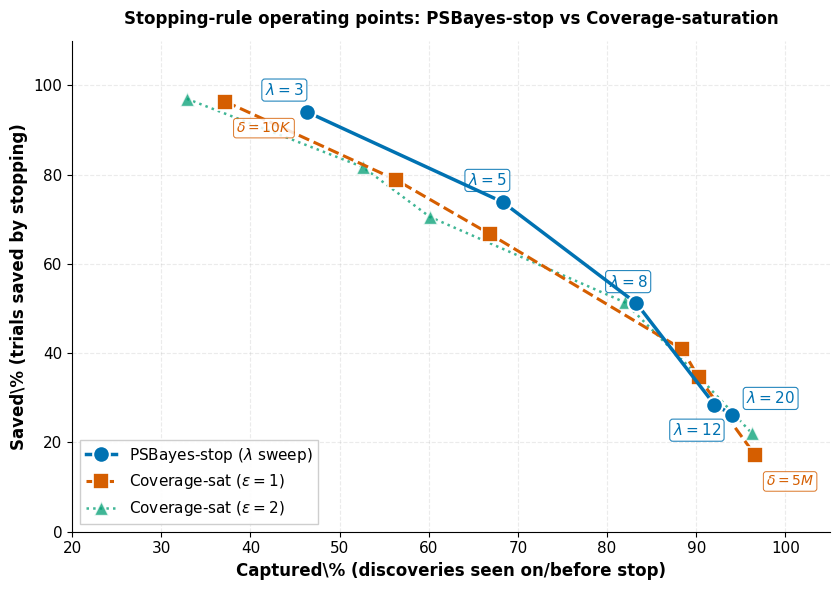


Saved: plots/rq4_psbayes_vs_covsat.jpg


In [28]:
# CELL-21: Coverage-saturation comparison (Green Fuzzing baseline)
# Implements Green Fuzzing's (S, delta, epsilon) coverage-saturation rule
# on the per-discovery data, then compares the resulting (Captured%, Saved%)
# frontier against PSBayes-stop (CELL-20).
#
# Rule: stop at the first round r where there exists j <= r with
#   t[r] - t[j] >= delta  AND  S[r] - S[j] <= epsilon,
# where t = cumulative trials and S = cumulative coverage features.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BENCHMARKS = ['freetype2.1', 'json.1', 'libpcap.1', 'libpng.1',
              'libxml.1', 'zlib.1', 're2-2014-12-09', 'libjpeg.1']

DELTAS = [10_000, 50_000, 100_000, 500_000, 1_000_000, 5_000_000]
EPSILONS = [0, 1, 2]

def coverage_sat_stop(d, delta_trials, eps):
    d = d.copy().reset_index(drop=True)
    ttd = d['TrialsToDisc'].values.astype(float)
    S   = d['OverallFeatures'].values.astype(float)
    n   = len(d)
    t   = np.cumsum(ttd)
    for r in range(n):
        j_arr = np.where(t[r] - t[:r+1] >= delta_trials)[0]
        if len(j_arr) == 0:
            continue
        j = j_arr[-1]
        if S[r] - S[j] <= eps:
            total_trials = ttd.sum()
            captured = (r + 1) / n * 100
            saved = ttd[r+1:].sum() / total_trials * 100 if total_trials > 0 else 0
            return r, captured, saved
    return None, 100.0, 0.0

results = []
for dt in DELTAS:
    for eps in EPSILONS:
        per_bench = []
        for fn in BENCHMARKS:
            d = pd.read_csv(f'./data/csv/{fn}.csv').iloc[1:].reset_index(drop=True)
            stop_r, cap, sav = coverage_sat_stop(d, dt, eps)
            per_bench.append((fn, stop_r, cap, sav))
        caps = [x[2] for x in per_bench]
        savs = [x[3] for x in per_bench]
        results.append({
            'delta_trials':    dt,
            'eps':             eps,
            'Captured%_mean':  np.mean(caps),
            'Captured%_std':   np.std(caps, ddof=1),
            'Saved%_mean':     np.mean(savs),
            'Saved%_std':      np.std(savs, ddof=1),
            'BenchsStopped':   sum(1 for x in per_bench if x[1] is not None),
        })

cov_df = pd.DataFrame(results)
cov_df.to_csv('./data/csv/coverage_sat_sweep_trials.csv', index=False)
print('Saved: data/csv/coverage_sat_sweep_trials.csv')
print()
print('Coverage-saturation rule sweep (averages across 8 benchmarks):')
print(cov_df.round(2).to_string(index=False))

# Per-benchmark detail at three representative operating points
per_bench_rows = []
for fn in BENCHMARKS:
    d = pd.read_csv(f'./data/csv/{fn}.csv').iloc[1:].reset_index(drop=True)
    row = {'Benchmark': fn}
    for dt in [50_000, 500_000, 5_000_000]:
        _, c, s = coverage_sat_stop(d, dt, 1)
        row[f'd{int(dt/1000)}K_eps1_Cap'] = round(c, 2)
        row[f'd{int(dt/1000)}K_eps1_Sav'] = round(s, 2)
    per_bench_rows.append(row)
pd.DataFrame(per_bench_rows).to_csv('./data/csv/coverage_sat_per_bench.csv', index=False)
print('\nSaved: data/csv/coverage_sat_per_bench.csv')

# Comparison plot: PSBayes-stop vs coverage-saturation (clean layout)
psb_avg = pd.read_csv('./data/csv/rq4_psbayes_stop_avg.csv')
cs_eps1 = cov_df[(cov_df['eps']==1) & (cov_df['BenchsStopped'] > 0)].sort_values('Captured%_mean').reset_index(drop=True)
cs_eps2 = cov_df[(cov_df['eps']==2) & (cov_df['BenchsStopped'] > 0)].sort_values('Captured%_mean').reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8.5, 6.0))
fig.patch.set_facecolor('white')

# PSBayes-stop curve (blue circles)
ax.plot(psb_avg['cap_mean'], psb_avg['sav_mean'], 'o-', color='#0072B2',
        markersize=12, linewidth=2.5, label='PSBayes-stop ($\\lambda$ sweep)',
        markeredgecolor='white', markeredgewidth=1.5, zorder=4)

# Coverage-sat eps=1 curve (red squares)
ax.plot(cs_eps1['Captured%_mean'], cs_eps1['Saved%_mean'], 's--',
        color='#D55E00', markersize=11, linewidth=2.2,
        label='Coverage-sat ($\\epsilon = 1$)',
        markeredgecolor='white', markeredgewidth=1.2, zorder=3)

# Coverage-sat eps=2 curve (green triangles, faded)
ax.plot(cs_eps2['Captured%_mean'], cs_eps2['Saved%_mean'], '^:',
        color='#009E73', markersize=10, linewidth=1.8,
        label='Coverage-sat ($\\epsilon = 2$)', alpha=0.75,
        markeredgecolor='white', markeredgewidth=1.0, zorder=2)

# Annotate PSBayes-stop lambda points (alternating above/below to avoid overlap)
lambda_offsets = {3: (-30, 12), 5: (-25, 12), 8: (-20, 12), 12: (-30, -22), 20: (10, 8)}
for _, r in psb_avg.iterrows():
    lam = int(r['lambda'])
    dx, dy = lambda_offsets.get(lam, (8, 12))
    ax.annotate(f'$\\lambda={lam}$', (r['cap_mean'], r['sav_mean']),
                xytext=(dx, dy), textcoords='offset points', fontsize=11,
                color='#0072B2', fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white',
                          edgecolor='#0072B2', alpha=0.85, linewidth=0.8))

# Annotate only the EXTREME coverage-sat eps=1 points (delta=10K and 5M) to reduce clutter
if len(cs_eps1) > 0:
    extremes = [cs_eps1.iloc[0], cs_eps1.iloc[-1]]
    for r in extremes:
        dt = r['delta_trials']
        lbl = f"{int(dt/1000)}K" if dt < 1_000_000 else f"{int(dt/1_000_000)}M"
        # Place label below for the leftmost, above for the rightmost
        dx, dy = (-15, -22) if r is cs_eps1.iloc[0] else (8, -22)
        ax.annotate(f'$\\delta={lbl}$', (r['Captured%_mean'], r['Saved%_mean']),
                    xytext=(dx, dy), textcoords='offset points', fontsize=10,
                    color='#D55E00', fontweight='bold',
                    bbox=dict(boxstyle='round,pad=0.2', facecolor='white',
                              edgecolor='#D55E00', alpha=0.85, linewidth=0.7))

ax.set_xlabel('Captured\\% (discoveries seen on/before stop)', fontsize=12, fontweight='bold')
ax.set_ylabel('Saved\\% (trials saved by stopping)', fontsize=12, fontweight='bold')
ax.set_title('Stopping-rule operating points: PSBayes-stop vs Coverage-saturation',
             fontsize=12, fontweight='bold', pad=12)
ax.grid(True, alpha=0.25, linestyle='--')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(loc='lower left', fontsize=11, frameon=True,
          edgecolor='#cccccc', fancybox=False, framealpha=0.95)
ax.set_xlim(20, 105)
ax.set_ylim(0, 110)
ax.tick_params(labelsize=11)

plt.tight_layout()
plt.savefig('./plots/rq4_psbayes_vs_covsat.jpg', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()
plt.close()
print('\nSaved: plots/rq4_psbayes_vs_covsat.jpg')

